# Итоговый проект "Временные ряды"
## Анализ и прогнозирование социально-экономических показателей регионов России

Данные - фактическое конечное потребление домашних хозяйств на душу населения по субъектам РФ за 2000-2023 годы, в текущих рыночных ценах (руб.). Файл rsdocs_1491005410458_wide_appendix_2025.csv.

Все графики по ходу сохраняются в папку figures/, оттуда они идут в отчёт.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score,root_mean_squared_error,mean_absolute_percentage_error
from statsmodels.tsa.stattools import adfuller,acf,pacf
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from sktime.forecasting.naive import NaiveForecaster

# statsmodels на коротких годовых рядах сыпет ConvergenceWarning/ValueWarning - на результат не влияет, глушим чтобы не засорять вывод
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns',40)
pd.set_option('display.width',200)
plt.rcParams['figure.figsize']=(12,4)
plt.rcParams['axes.grid']=True

RANDOM_STATE=42
DATA_PATH='data/rsdocs_1491005410458_wide_appendix_2025.csv'
FIG_DIR='figures'
os.makedirs(FIG_DIR,exist_ok=True)

def savefig(name):
    # все картинки складываем в figures/ - потом они вставляются в отчёт
    plt.savefig(os.path.join(FIG_DIR,f'{name}.png'),dpi=150,bbox_inches='tight')

## Этап 1. Загрузка и подготовка данных

### 1.1. Загрузка файла

In [4]:
df=pd.read_csv(DATA_PATH)
print('записей:',df.shape[0],'| колонок:',df.shape[1])
df.head(3)

записей: 96 | колонок: 29


,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,Unnamed: 28
0,Фактическое конечное потребление домашних хозя...,NaN,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"24964,9","33073,8","42325,5",50809,"63177,6","79943,6",99969,"124846,2",156161,"164847,7",183266,214113,"239135,9","262359,5","279922,2","296330,1","335157,9","352032,4","378631,5","396539,7","409455,2","482117,7","537330,3","605276,8",NaN
1,Центральный федеральный округ,3.000000e+01,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"37398,9","48743,1","60043,2","71997,2","86784,2","106512,6","129801,3","159400,6","196202,6","207213,9","231720,5",272574,"302078,7","326737,5","357669,5","371888,6","428461,6","449367,4","483617,8","504322,7","522640,3","622652,4","670468,1","745978,7",NaN
2,Белгородская область,1.400000e+10,Фактическое конечное потребление домашних хозя...,в текущих рыночных ценах; рублей,"19420,9","22799,1","26386,5",31254,"39422,8","48000,4","64017,4","83720,9","110581,7","121935,4","138080,2","162871,1","187390,1","212122,3","234785,7","252179,1",299984,"321377,9","343531,1",362467,386681,"432635,6",488454,514718,NaN


### 1.2. Структура: колонки и типы данных

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   region_name     96 non-null     str    
 1   region_code     94 non-null     float64
 2   indicator_name  96 non-null     str    
 3   measure_unit    96 non-null     str    
 4   2000            92 non-null     str    
 5   2001            92 non-null     str    
 6   2002            92 non-null     str    
 7   2003            92 non-null     str    
 8   2004            92 non-null     str    
 9   2005            92 non-null     str    
 10  2006            92 non-null     str    
 11  2007            92 non-null     str    
 12  2008            92 non-null     str    
 13  2009            92 non-null     str    
 14  2010            92 non-null     str    
 15  2011            94 non-null     str    
 16  2012            94 non-null     str    
 17  2013            94 non-null     str    
 18  201

In [6]:
YEARS=[c for c in df.columns if c.isdigit()]
print('годовых колонок:',len(YEARS),f'({YEARS[0]}-{YEARS[-1]})')
print('служебные колонки:',[c for c in df.columns if not c.isdigit()])
print('показатель:',df['indicator_name'].unique()[0])
print('единица измерения:',df['measure_unit'].unique())

# почему годы прочитались как str: десятичная запятая и символ "…" вместо числа
raw=df[YEARS]
print('пустых ячеек в годах:',int(raw.isna().sum().sum()))
print('ячеек с "…":',int(raw.apply(lambda c:c.astype(str).str.strip().eq('…')).sum().sum()))
print('пример значения:',repr(raw.iloc[0,0]))

годовых колонок: 24 (2000-2023)
служебные колонки: ['region_name', 'region_code', 'indicator_name', 'measure_unit', 'Unnamed: 28']
показатель: Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в текущих рыночных ценах; рублей)
единица измерения: <ArrowStringArray>
['в текущих рыночных ценах; рублей']
Length: 1, dtype: str
пустых ячеек в годах: 50
ячеек с "…": 14
пример значения: '24964,9'


Факты по датасету: 
- строка - одна территория 
- годы 2000-2023 идут отдельными колонками, плюс в конце пустая колонка Unnamed: 28 (хвостовая запятая в CSV). 
- Годы прочитались стрингами, потому что в floats запятая, а часть пропусков записана символом "…". Фикс: запятые в точку, пропуски делаем НаН.
- Ещё одна мелочь: в "Калинингpадская область" буква р латинская и у этой строки нет кода региона, фильтр по коду её бы молча выкинул. Поэтому названия я чищу, а тип территории определяю по названию, а не по коду.

In [7]:
df=df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])

# фиксим вставки латиницы в слова которые написаны кириллицей
LAT2CYR=str.maketrans('aceopxyABCEHKMOPTX','асеорхуАВСЕНКМОРТХ')
fixed_names=df['region_name'].str.translate(LAT2CYR).str.strip()
print('исправлены названия:',df.loc[fixed_names!=df['region_name'],'region_name'].tolist())
df['region_name']=fixed_names

def to_num(col):
    # ... и пустые в nan, грохаем пробелы-разделители тысяч, запятую в числах в точку
    s=col.astype(str).str.strip().replace({'…':np.nan,'...':np.nan,'nan':np.nan,'':np.nan})
    s=s.str.replace('\xa0','',regex=False).str.replace(' ','',regex=False).str.replace(',','.',regex=False)
    return pd.to_numeric(s,errors='raise')

df[YEARS]=df[YEARS].apply(to_num)
print(df[YEARS].dtypes.value_counts())

исправлены названия: ['Калинингpадская область']
float64    24
Name: count, dtype: int64


Дальше размечаю тип каждой строки: РФ в целом, федеральный округ, дублирующий агрегат ("... без автономного округа") или обычный субъект.

In [8]:
def territory_type(name):
    if name.startswith('Фактическое') or name.startswith('Российская Федерация'):
        return 'РФ'
    if 'федеральный округ' in name:
        return 'ФО'
    if ' без ' in name:
        return 'дубль-агрегат'
    return 'субъект'

df['type']=df['region_name'].map(territory_type)
df['type'].value_counts()

type
субъект          85
ФО                8
дубль-агрегат     2
РФ                1
Name: count, dtype: int64

### 1.3. Проверка пропусков

In [9]:
def years_span(yrs):
    #годы подряд схлопываем в диапазон. Типа: "2000-2013"
    yrs=[int(y) for y in yrs]
    if len(yrs)>1 and yrs==list(range(yrs[0],yrs[-1]+1)):
        return f'{yrs[0]}-{yrs[-1]}'
    return ', '.join(map(str,yrs))

na=df[YEARS].isna()
df['n_missing']=na.sum(axis=1)
df['missing_years']=[years_span([y for y in YEARS if na.loc[i,y]]) if na.loc[i].any() else '' for i in df.index]
print('строк с пропусками:',(df['n_missing']>0).sum(),'| всего пропусков:',int(na.sum().sum()))
df.loc[df['n_missing']>0,['region_name','type','n_missing','missing_years']]

строк с пропусками: 8 | всего пропусков: 64


,region_name,type,n_missing,missing_years
24,Ненецкий автономный округ,субъект,3,2000-2002
25,Архангельская область без автономного округа,дубль-агрегат,11,2000-2010
36,Республика Крым,субъект,14,2000-2013
41,г. Севастополь,субъект,14,2000-2013
48,Чеченская Республика,субъект,5,2000-2004
69,Ханты-Мансийский автономный округ – Югра,субъект,3,2000-2002
70,Ямало-Ненецкий автономный округ,субъект,3,2000-2002
71,Тюменская область без автономных округов,дубль-агрегат,11,2000-2010


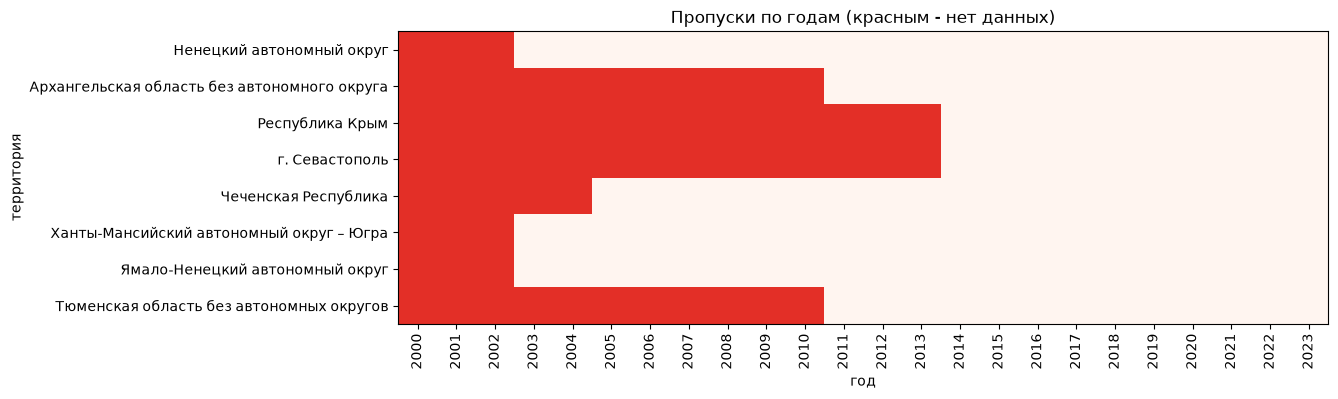

In [10]:
rows=df.index[df['n_missing']>0]
fig,ax=plt.subplots(figsize=(12,3.8))
ax.imshow(na.loc[rows].values,aspect='auto',cmap='Reds',vmin=0,vmax=1.5)
ax.set_yticks(range(len(rows)),df.loc[rows,'region_name'])
ax.set_xticks(range(len(YEARS)),YEARS,rotation=90)
ax.set(title='Пропуски по годам (красным - нет данных)',xlabel='год',ylabel='территория')
ax.grid(False)
savefig('01_missing')
plt.show()

Пропуски все "с начала ряда": 
- у Крыма и Севастополя нет 2000-2013 (данные с 2014 года)
- у двух строк "без автономного округа" нет 2000-2010, 
- у Чечни 2000-2004, 
- у трёх автономных округов (НАО, ХМАО, ЯНАО) 2000-2002. 

Внутри остальных рядов пропусков нет. По таске "длительные начальные фрагменты" не восстанавливаем - все эти позиции выбрасываем

### 1.4. Выбор строк для дропа
```
Исключите из анализа строки, соответствующие Российской Федерации в целом, 
федеральным округам, а также дублирующиеся агрегированные записи 
```


In [11]:
def exclusion_reason(r):
    if r['type']=='РФ':
        return 'агрегат по РФ в целом'
    if r['type']=='ФО':
        return 'агрегат по ФО'
    if r['type']=='дубль-агрегат':
        return f'дублирующий агрегат, нет данных за {r["missing_years"]}'
    if r['n_missing']>0:
        return f'неполный ряд нет данных за {r["missing_years"]}'
    return None

df['exclude_reason']=df.apply(exclusion_reason,axis=1)
excluded=df.loc[df['exclude_reason'].notna(),['region_name','type','n_missing','exclude_reason']].reset_index(drop=True)
print('исключено:',len(excluded),'| осталось субъектов:',int(df['exclude_reason'].isna().sum()))
excluded

исключено: 17 | осталось субъектов: 79


,region_name,type,n_missing,exclude_reason
0,Фактическое конечное потребление домашних хозя...,РФ,0,агрегат по РФ в целом
1,Центральный федеральный округ,ФО,0,агрегат по ФО
2,Северо-Западный федеральный округ,ФО,0,агрегат по ФО
3,Ненецкий автономный округ,субъект,3,неполный ряд нет данных за 2000-2002
4,Архангельская область без автономного округа,дубль-агрегат,11,"дублирующий агрегат, нет данных за 2000-2010"
5,Южный федеральный округ,ФО,0,агрегат по ФО
6,Республика Крым,субъект,14,неполный ряд нет данных за 2000-2013
7,г. Севастополь,субъект,14,неполный ряд нет данных за 2000-2013
8,Северо-Кавказский федеральный округ,ФО,0,агрегат по ФО
9,Чеченская Республика,субъект,5,неполный ряд нет данных за 2000-2004


Из 96 строк дропаем 17: 
- строка по РФ
- 8 федеральных округов
- 2 дублирующих агрегата
- 6 субъектов с неполным рядом. 

Архангельская и Тюменская области в файле даны вместе с автономными округами, а сами АО отдельно выкинуты из-за неполного ряда, так что двойного счёта не остаётся. 
К слову, у Южного и Северо-Кавказского ФО значение за 2000 год подозрительно большое (около 96 и 76 тыс. руб. при 15-20 тыс. у их же регионов), но они и так исключены.

### 1.5. Перевод из широкого формата в длинный и ряды по регионам, дроп бесполезного

In [12]:
long=df.melt(id_vars=['region_name','type','exclude_reason'],value_vars=YEARS,var_name='year',value_name='value')
long['year']=long['year'].astype(int)
print('wide:',df.shape,'-> long:',long.shape)

long=long[long['exclude_reason'].isna()].drop(columns=['type','exclude_reason'])
long=long.sort_values(['region_name','year']).reset_index(drop=True)
print('long по субъектам:',long.shape)
long.head()

wide: (96, 32) -> long: (2304, 5)
long по субъектам: (1896, 3)


,region_name,year,value
0,Алтайский край,2000,15751.1
1,Алтайский край,2001,21539.7
2,Алтайский край,2002,28855.5
3,Алтайский край,2003,35772.7
4,Алтайский край,2004,44268.9


In [13]:
# делаем словарик на каждый регион по годам
# индекс - год
series={r:pd.Series(g['value'].values,index=pd.PeriodIndex(g['year'].astype(str),freq='Y'),name=r) for r,g in long.groupby('region_name')}
panel=pd.DataFrame(series)
panel.index.name='year'
print('рядов:',len(series),'| длина:',panel.shape[0],'| пропусков:',int(panel.isna().sum().sum()))
series['Курская область'].head()

рядов: 79 | длина: 24 | пропусков: 0


year
2000    15690.0
2001    20964.7
2002    26421.6
2003    32000.0
2004    41463.6
Freq: Y-DEC, Name: Курская область, dtype: float64

### 1.6. Точечные аномалии

Пропуски обработали, но хорошо бы проверить одиночные выбросы. Считаю отклонение логарифма от среднего соседних лет: для гладко растущего ряда оно небольшое, выбросы сходу будут видны

In [14]:
def spike_score(p):
    lp=np.log(p)
    return (lp-(lp.shift(1)+lp.shift(-1))/2).abs()

spike_score(panel).stack().sort_values(ascending=False).head(6).to_frame('отклонение(лог)')

отклонение(лог)
year                                            
2004 Красноярский край                  0.943155
2005 Красноярский край                  0.497263
2003 Красноярский край                  0.478057
     Республика Калмыкия                0.211952
2002 Чукотский автономный округ         0.170073
2008 Кемеровская область                0.147161

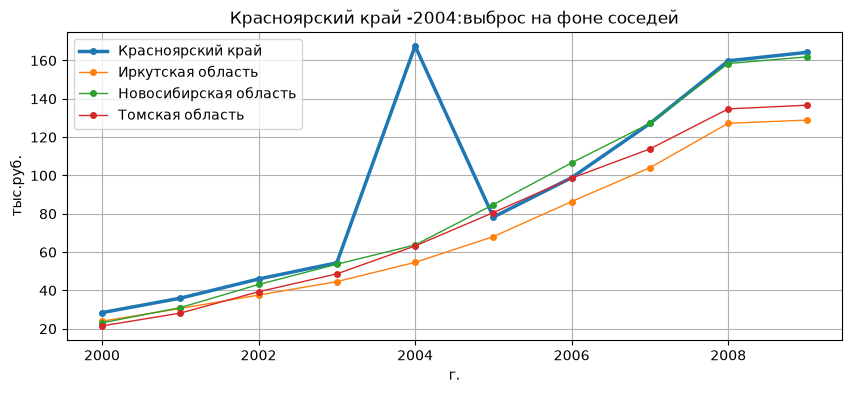

In [15]:
fig,ax=plt.subplots(figsize=(10,4))
for r in ['Красноярский край','Иркутская область','Новосибирская область','Томская область']:
    ax.plot(panel.index.year[:10],panel[r].iloc[:10]/1e3,marker='o',ms=4,label=r,lw=2.5 if r=='Красноярский край' else 1)
ax.set(title='Красноярский край -2004:выброс на фоне соседей',xlabel='г.',ylabel='тыс.руб.')
ax.legend()
savefig('02_krasnoyarsk_spike')
plt.show()

Красноярский край в 2004г. - какой-то явный косяк в данных: 54-167-78к.руб., то есть рост в 3 раза и сразу падение вдвое. Если предположить что там лишняя единичка в начале числа - 67.6к. то тогда хорошо ложится в траекторию). 

Остальные отклонения сильно меньше, это обычные колебания. 

Как фиксим - эту точку внутри ряда заменяю средним геометрическим соседей. это не восстановление длинного куска, так что условию не противоречит. Без этого признак "максимальное годовое падение" у Красноярска был бы -53% и он стал бы отдельным кластером из одного региона.

In [16]:
SPIKE_THR=0.5   # порог в лог-единицах: следующее после Красноярска отклонение около 0.2
fixed=[]
while True:
    s=spike_score(panel).stack()
    (yr,reg),v=s.idxmax(),s.max()
    if v<SPIKE_THR:
        break
    old=panel.loc[yr,reg]
    panel.loc[yr,reg]=np.sqrt(panel.loc[yr-1,reg]*panel.loc[yr+1,reg])
    fixed.append({'регион':reg,'год':str(yr),'было':old,'стало':panel.loc[yr,reg]})
series={r:panel[r] for r in panel}
pd.DataFrame(fixed)

,регион,год,было,стало
0,Красноярский край,2004,167593.2,65260.334273


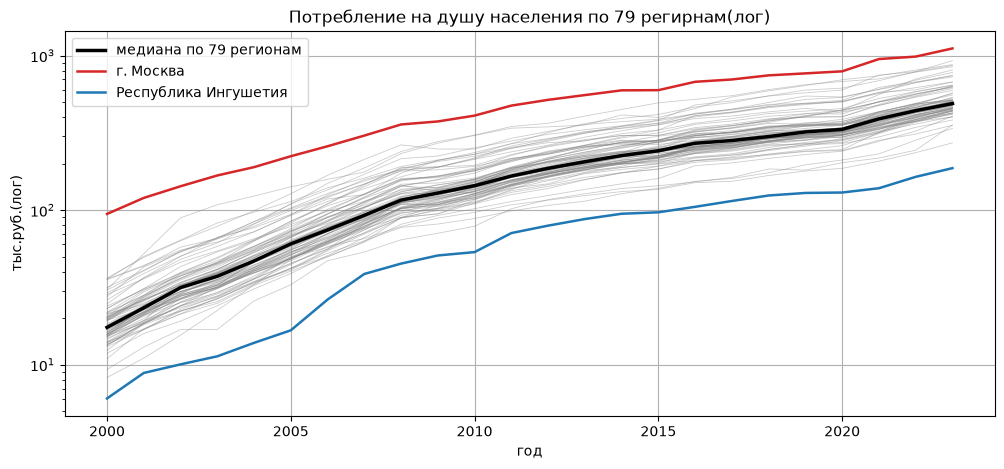

In [17]:
fig,ax=plt.subplots(figsize=(12,5))
t=panel.index.year
for r in panel:
    ax.plot(t,panel[r]/1e3,color='gray',lw=0.6,alpha=0.4)
ax.plot(t,panel.median(axis=1)/1e3,color='k',lw=2.5,label='медиана по 79 регионам')
ax.plot(t,panel['г. Москва']/1e3,color='C3',lw=1.8,label='г. Москва')
ax.plot(t,panel['Республика Ингушетия']/1e3,color='C0',lw=1.8,label='Республика Ингушетия')
ax.set_yscale('log')
ax.set(title='Потребление на душу населения по 79 регирнам(лог)',xlabel='год',ylabel='тыс.руб.(лог)')
ax.legend()
savefig('03_all_regions')
plt.show()

In [21]:
med = panel.median(axis=1)
print(med.iloc[0]/1e3, med.iloc[-1]/1e3, med.iloc[-1]/med.iloc[0])
y = panel.index.year
msk = panel['г. Москва']
print(msk[y==2000].iloc[0]/1e3, msk[y==2023].iloc[0]/1e3)
g = (panel.pct_change()*100).median(axis=1)
g.index = y
print(g.loc[[2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023]])

17.415200000000002 489.08340000000004 28.08370848454224
94.4114 1111.4526
year
2001    33.441938
2002    29.875123
2003    21.332468
2004    26.526961
2005    26.593654
2006    25.833726
2007    25.510973
2008    26.274878
2009     9.074605
2010    11.493794
2011    17.280906
2012    11.952765
2013    10.867400
2014     9.180607
2015     6.853011
2016    11.525767
2017     5.280715
2018     7.859706
2019     5.512136
2020     3.767190
2021    14.599961
2022    13.414530
2023    11.790993
dtype: float64


**вывод:** Все 79 рядов растут почти параллельно. Медиана за 23г. выросла с 17.4 до 489тыс. руб., т.е. в 28 раз. Это текущие цены, так что большая часть этого роста - инфляция. Поэтому корректно сравнивать регионы между собой внутри одного года, а не например:Курск 23г. с Курском 2000-го.

Разброс уровней огромный. Москва в 2000 году была выше медианы в 5.4 раза (94.4 против 17.4 тыс.), к 2023 разрыв сжался до 2.3 раза (1111 против 489), т.е. регионы догоняли столицу. Ингушетия всё время внизу: 6к. в 2000 и 187 тыс. в 2023. 

На медиане видны изломы - 2009, 2015 и 2020 годы, где рост резко замедляется (медианный темп 9.1%, 6.9% и 3.8% против 25-26% в 2004-2008), а после 2020 снова разгон до 12-15% в год.
Я в своё время писал диплом по мировому кризису 2008 (стартанул в 2007 как пузырь с недвижимостью в США), поэтому 2009 логичен (с отложенным лагом в год. До "моей" Беларуси вообще в 2011 докатилось). В 2014 - обвал цены на нефть(и как следствие - курса рубля) и частично из-за санкций после Крыма. До потребителей докатилось к 2015. 2020 год, это естесственно пандемия. 

## Этап 2. Кластерный анализ регионов

### 2.1. Признаки рядов

Ряды в текущих ценах, поэтому абс.величины в основном про масштаб и инфляцию. Считаем по рекоменадции:
```
Рекомендуемый набор признаков для каждого региона (выберите не менее четырёх):

- среднее значение за период (отражает общий уровень потребления в регионе);
-коэффициент вариации (стандартное отклонение, делённое на среднее — характеризует относительную волатильность ряда, не зависящую от масштаба);
- средний годовой темп роста (или медианный темп роста);
- относительное изменение за весь период (значение в последнем году относительно первого);
- максимальное годовое падение (наибольшее отрицательное изменение за один год);
- доля лет с отрицательной динамикой (число лет, когда показатель снизился относительно предыдущего года).
```
комменты:
- средний годовой темп роста - считаем CAGR
- максимальное годовое падение - минимальный годовой темп, может быть и положительным

In [22]:
def ts_features(y):
    g=y.pct_change().dropna() #годовые темпы роста
    return pd.Series({
        'mean':y.mean(), #уровень потребления
        'cv':y.std()/y.mean(),  #относительная волатильность,без масштаба
        'cagr':(y.iloc[-1]/y.iloc[0])**(1/(len(y)-1))-1,# ср.год. темп роста
        'total_change':y.iloc[-1]/y.iloc[0], # во сколько раз вырос за период
        'max_drop':g.min(), #худший год
        'neg_share':(g<0).mean(), # доля лет со снижением
    })

feats=panel.apply(ts_features).T
feats.describe().T

,count,mean,std,min,25%,50%,75%,max
mean,79.0,209967.380873,65290.157542,75110.612500,175928.937500,191444.666667,231272.877083,504230.937500
cv,79.0,0.713739,0.048357,0.581835,0.685066,0.716346,0.748855,0.819000
cagr,79.0,0.155456,0.010992,0.113165,0.150367,0.157098,0.161453,0.186743
total_change,79.0,28.362331,5.953603,11.772441,25.075084,28.675522,31.264465,51.310448
max_drop,79.0,0.014389,0.028859,-0.093622,0.000322,0.016325,0.037780,0.066856
neg_share,79.0,0.011007,0.020260,0.000000,0.000000,0.000000,0.000000,0.086957


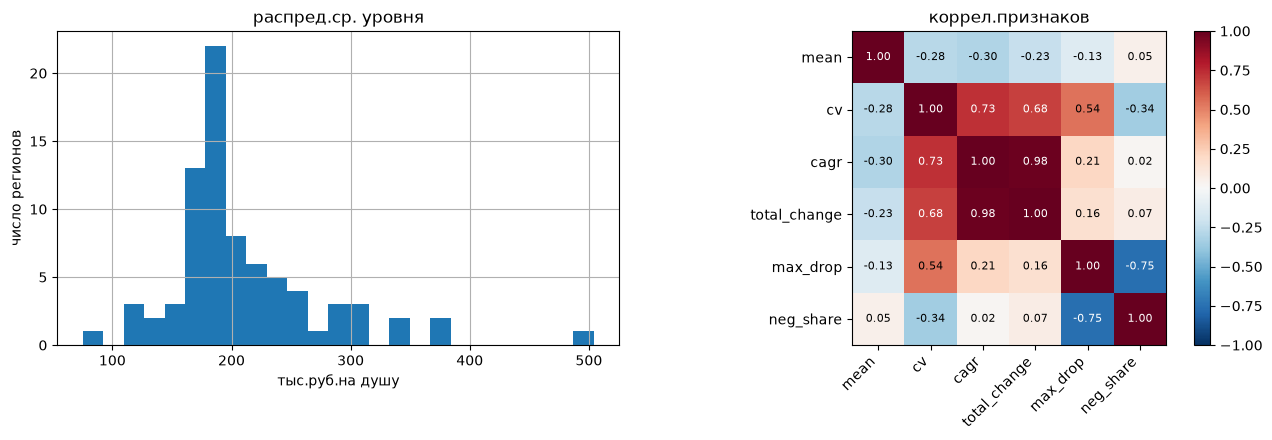

асимметрия mean: 1.69 | асимметрия log(mean): 0.16


In [25]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
axes[0].hist(feats['mean']/1e3,bins=25)
axes[0].set(title='распред.ср. уровня',xlabel='тыс.руб.на душу',ylabel='число регионов')
c=feats.corr()
im=axes[1].imshow(c,cmap='RdBu_r',vmin=-1,vmax=1)
axes[1].set_xticks(range(len(c)),c.columns,rotation=45,ha='right')
axes[1].set_yticks(range(len(c)),c.columns)
for i in range(len(c)):
    for j in range(len(c)):
        axes[1].text(j,i,f'{c.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8,color='white' if abs(c.iloc[i,j])>0.6 else 'black')
axes[1].set_title('коррел.признаков')
axes[1].grid(False)
plt.colorbar(im,ax=axes[1])
plt.tight_layout()
savefig('04_features')
plt.show()
print('асимметрия mean:',round(feats['mean'].skew(),2),'| асимметрия log(mean):',round(np.log(feats['mean']).skew(),2))

In [27]:
print((feats['mean']/1e3).sort_values(ascending=False).head(20).round(1))

г. Москва                     504.2
Сахалинская область           371.8
Чукотский автономный округ    369.8
г. Санкт-Петербург            341.2
Магаданская область           334.8
Тюменская область             313.3
Республика Саха (Якутия)      309.1
Камчатский край               305.6
Мурманская область            294.4
Московская область            288.3
Хабаровский край              282.9
Свердловская область          271.0
Краснодарский край            263.4
Республика Коми               254.9
Архангельская область         253.9
Республика Татарстан          247.0
Приморский край               236.7
Республика Карелия            234.7
Амурская область              231.9
Самарская область             231.3
Name: mean, dtype: float64


Средний уровень сильно скошен вправо (асимметрия 1.69): основная масса регионов в районе 170-230 тыс., а дальше хвост из северных и сырьевых регионов и Москва - 504 тыс. 
В K-means с евклидовым расстоянием такой хвост легко перетягивает на себя отдельный кластер, поэтому уровень беру в логарифме, асимметрия падает до 0.16.

total_change выкидываю: с cagr корреляция 0.98, что логично - total_change = (1 + cagr)^23, одна и та же величина в другой шкале. С ней темп роста считался бы в расстоянии дважды. cv тоже связан с cagr (0.73) - чем быстрее рос регион, тем сильнее разъезжаются начало и конец ряда - но он несёт ещё и информацию о форме траектории, так что оставляю. 

Итого пять признаков: log(mean), cv, cagr, max_drop и neg_share, из них четыре относительные и от масштаба экономики не зависят.

In [28]:
FEATURES=['log_mean','cv','cagr','max_drop','neg_share']
feats['log_mean']=np.log(feats['mean'])
X=feats[FEATURES]
#стандартизация:признаки в разных ед.: - лог.руб, доли, без неё k-means смотрел бы только на самый "широкий"
Xs=StandardScaler().fit_transform(X)
pd.DataFrame(Xs,columns=FEATURES).describe().loc[['mean','std']].round(3)

,log_mean,cv,cagr,max_drop,neg_share
mean,0.000,-0.000,0.000,0.000,0.000
std,1.006,1.006,1.006,1.006,1.006


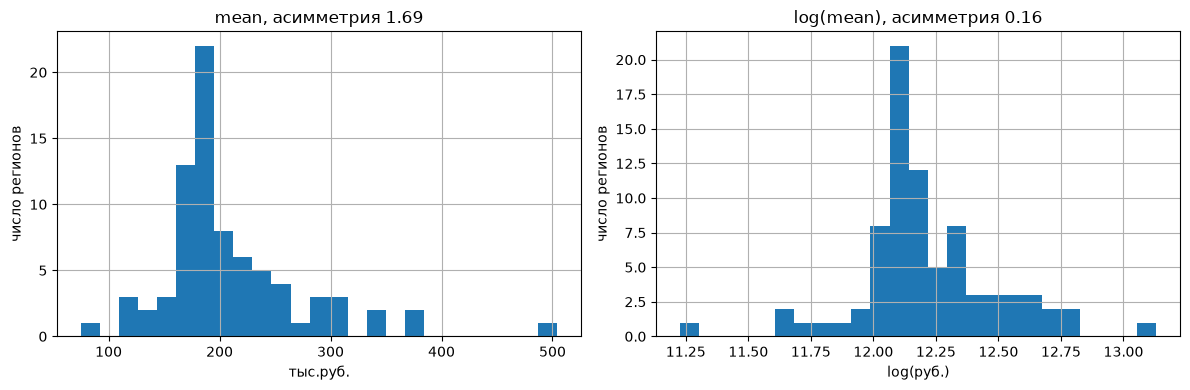

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(feats['mean']/1e3, bins=25)
axes[0].set(title=f"mean, асимметрия {feats['mean'].skew():.2f}", xlabel='тыс.руб.', ylabel='число регионов')
axes[1].hist(feats['log_mean'], bins=25)
axes[1].set(title=f"log(mean), асимметрия {feats['log_mean'].skew():.2f}", xlabel='log(руб.)', ylabel='число регионов')
plt.tight_layout()
savefig('04b_log_mean')
plt.show()

### 2.2.k-means для к=2,3,4
Беру k-means: признаков мало, все числовые и после стандартизации в одной шкале, регионов 79 - для такого случая это самый простой вариант, а центроиды сразу дают профиль кластера и "самый типичный" регион (для 3 этапа). 

n_init=50, чтобы результат не зависел от неудачной инициализации.

In [33]:
PROFILE=['mean','cv','cagr','total_change','max_drop','neg_share']

def profile(labels):
    # ср.признаки по кластеру в норм.ед.
    p=feats.assign(cluster=labels).groupby('cluster')[PROFILE].mean()
    p['n']=pd.Series(labels).value_counts()
    p['mean']=p['mean']/1e3
    p[['cagr','max_drop','neg_share']]*=100
    return p.rename(columns={'mean':'mean, тыс.руб','cagr':'cagr, %','max_drop':'max_drop, %','neg_share':'neg_share, %'})

km_res={}
rows=[]
for k in range(2,5):
    km=KMeans(n_clusters=k,n_init=50,random_state=RANDOM_STATE).fit(Xs)
    km_res[k]=km
    rows.append({'k':k,'silhouette':silhouette_score(Xs,km.labels_),'inertia':km.inertia_,'размеры класт.':sorted(np.bincount(km.labels_).tolist(),reverse=True)})
sil=pd.DataFrame(rows).set_index('k')
sil

,silhouette,inertia,размеры класт.
k,,,
2,0.405509,259.581767,"[58, 21]"
3,0.321283,205.105249,"[45, 18, 16]"
4,0.268260,169.151052,"[31, 28, 14, 6]"


In [34]:
for k in km_res:
    print(f'--- k={k}')
    display(profile(km_res[k].labels_).round(2))

--- k=2


,"mean, тыс.руб",cv,"cagr, %",total_change,"max_drop, %","neg_share, %",n
cluster,,,,,,,
0,232.66,0.68,15.17,26.91,-2.17,4.14,21
1,201.75,0.73,15.68,28.89,2.75,0.00,58


--- k=3


,"mean, тыс.руб",cv,"cagr, %",total_change,"max_drop, %","neg_share, %",n
cluster,,,,,,,
0,198.20,0.74,16.01,30.66,3.08,0.00,45
1,235.81,0.67,14.20,21.52,1.18,0.27,16
2,216.41,0.69,15.58,28.71,-2.44,4.59,18


--- k=4


,"mean, тыс.руб",cv,"cagr, %",total_change,"max_drop, %","neg_share, %",n
cluster,,,,,,,
0,205.26,0.70,16.01,30.96,-1.83,4.66,14
1,210.22,0.75,16.25,32.10,3.35,0.00,31
2,194.28,0.70,15.00,25.07,1.98,0.00,28
3,292.89,0.62,13.37,18.35,-3.36,3.62,6


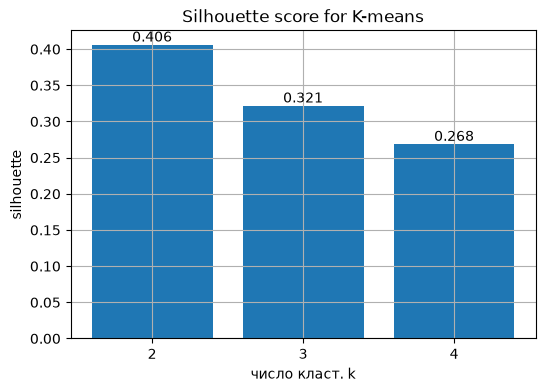

In [35]:
fig,ax=plt.subplots(figsize=(6,4))
ax.bar(sil.index.astype(str),sil['silhouette'])
for k,v in sil['silhouette'].items():
    ax.text(str(k),v+0.005,f'{v:.3f}',ha='center')
ax.set(title='Silhouette score for K-means',xlabel='число класт. k',ylabel='silhouette')
savefig('05_silhouette')
plt.show()

По силуэту лучший вариант k=2 (0.406), дальше 0.321 и 0.268 для k - 3 и 4. Но если смотреть профили, k=2 делит регионы по сути по одному признаку: были ли вообще годы со снижением (21 регион) или нет (58). Это правда, но маловато - внутри большой группы оказываются и Москва с её 11% роста в год, и Краснодарский край с 17.5%.

При k=3 из "беспросадочной" группы выделяются 16 регионов с высоким стартом и заметно более медленным ростом (cagr 14.2% против 16.0%, рост за период в 21.5 раза против 30.7). Появляется вторая содержательная ось - догоняющий рост против уже высокого уровня. k=4 силуэт роняет ещё ниже и делает две вещи: дробит "устойчивый рост" на чуть быстрее и чуть медленнее (16.3% против 15.0%) и выделяет 6 регионов - Москва, Самарская и Тюменская области, Пермский край, Кузбасс, Якутия, где смешаны высокий уровень и просадки. Интерпретировать это уже сложнее. Так что беру k=3: силуэт не макс, но положительный и заметный, а группы нормально читаются экономически.

In [41]:
K=3
km=km_res[K]
feats['cluster']=km.labels_
prof=profile(km.labels_)

# названия по профилю, а не по номеру потому что номера у к-минс произвольные
c_drop=prof['neg_share, %'].idxmax()
rest=prof.drop(c_drop)
c_slow=rest['cagr, %'].idxmin()
c_fast=rest.drop(c_slow).index[0]
NAMES={c_fast:'A: устойчивый быстрый рост',c_drop:'B:рост с просадками',c_slow:'C:высокий старт, медленный рост'}
ORDER=[c_fast,c_drop,c_slow]
feats['cluster_name']=feats['cluster'].map(NAMES)

prof_named=prof.loc[ORDER].rename(index=NAMES)
prof_named['2000,тыс.руб(медиана)']=[panel.iloc[0][feats['cluster']==c].median()/1e3 for c in ORDER]
prof_named['2023, тыс.руб(медиана)']=[panel.iloc[-1][feats['cluster']==c].median()/1e3 for c in ORDER]
prof_named.round(2)

,"mean, тыс.руб",cv,"cagr, %",total_change,"max_drop, %","neg_share, %",n,"2000,тыс.руб(медиана)","2023, тыс.руб(медиана)"
cluster,,,,,,,,,
A: устойчивый быстрый рост,198.20,0.74,16.01,30.66,3.08,0.00,45,16.18,479.07
B:рост с просадками,216.41,0.69,15.58,28.71,-2.44,4.59,18,17.94,477.26
"C:высокий старт, медленный рост",235.81,0.67,14.20,21.52,1.18,0.27,16,23.51,519.62


In [42]:
for c in ORDER:
    regs=feats.index[feats['cluster']==c].tolist()
    print(f'{NAMES[c]} ({len(regs)}):')
    print('   '+', '.join(regs))

A: устойчивый быстрый рост (45):
   Амурская область, Архангельская область, Белгородская область, Брянская область, Владимирская область, Волгоградская область, Еврейская автономная область, Ивановская область, Кабардино-Балкарская Республика, Калининградская область, Калужская область, Кировская область, Костромская область, Краснодарский край, Курская область, Ленинградская область, Липецкая область, Магаданская область, Московская область, Нижегородская область, Оренбургская область, Орловская область, Пензенская область, Псковская область, Республика Адыгея, Республика Алтай, Республика Бурятия, Республика Ингушетия, Республика Карелия, Республика Марий Эл, Республика Мордовия, Республика Северная Осетия – Алания, Республика Татарстан, Республика Тыва, Республика Хакасия, Рязанская область, Саратовская область, Сахалинская область, Тверская область, Тульская область, Удмуртская Республика, Ульяновская область, Чувашская Республика, Ярославская область, г. Санкт-Петербург
B:рост с 

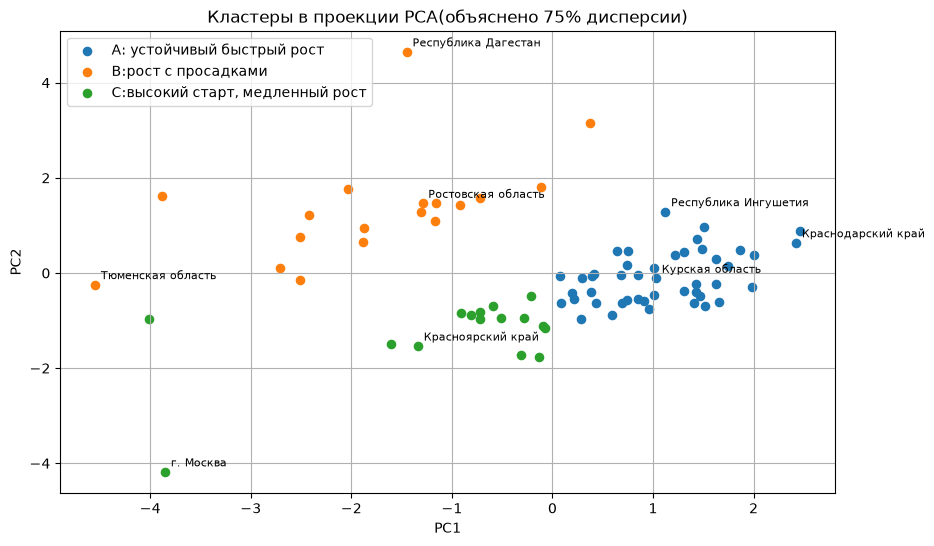

,log_mean,cv,cagr,max_drop,neg_share
PC1,-0.23,0.56,0.41,0.53,-0.43
PC2,-0.35,0.25,0.58,-0.39,0.58


In [43]:
pca=PCA(n_components=2,random_state=RANDOM_STATE)
P=pca.fit_transform(Xs)
fig,ax=plt.subplots(figsize=(10,6))
for i,c in enumerate(ORDER):
    m=feats['cluster'].values==c
    ax.scatter(P[m,0],P[m,1],s=35,label=NAMES[c],color=f'C{i}')
for r in ['г. Москва','Республика Ингушетия','Республика Дагестан','Краснодарский край','Тюменская область','Курская область','Ростовская область','Красноярский край']:
    i=feats.index.get_loc(r)
    ax.annotate(r,P[i],fontsize=8,xytext=(4,4),textcoords='offset points')
ax.set(title=f'Кластеры в проекции PCA(объяснено {pca.explained_variance_ratio_.sum()*100:.0f}% дисперсии)',xlabel='PC1',ylabel='PC2')
ax.legend()
savefig('06_clusters_pca')
plt.show()
pd.DataFrame(pca.components_,columns=FEATURES,index=['PC1','PC2']).round(2)

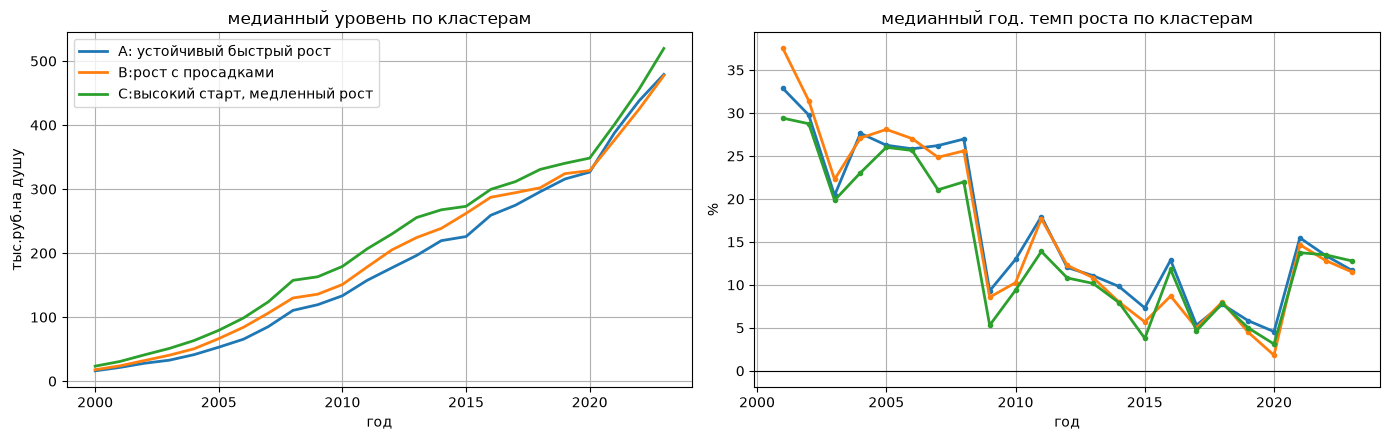

In [45]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
t=panel.index.year
growth=panel.pct_change()*100
for i,c in enumerate(ORDER):
    cols=feats.index[feats['cluster']==c]
    axes[0].plot(t,panel[cols].median(axis=1)/1e3,color=f'C{i}',lw=2,label=NAMES[c])
    axes[1].plot(t[1:],growth[cols].median(axis=1).iloc[1:],color=f'C{i}',lw=2,marker='o',ms=3,label=NAMES[c])
axes[0].set(title='медианный уровень по кластерам',xlabel='год',ylabel='тыс.руб.на душу')
axes[1].axhline(0,color='k',lw=0.8)
axes[1].set(title='медианный год. темп роста по кластерам',xlabel='год',ylabel='%')
axes[0].legend()
plt.tight_layout()
savefig('07_clusters_dynamics')
plt.show()

In [46]:
#сколько регионов кластера снижались в каждый год - видно, где просадки кластера В
neg_years=(growth<0).T.groupby(feats['cluster_name']).sum().loc[:,lambda d:d.sum()>0]
neg_years.columns=neg_years.columns.year
neg_years

year,2009,2010,2015,2018,2019,2020
cluster_name,,,,,,
A: устойчивый быстрый рост,0,0,0,0,0,0
B:рост с просадками,4,1,4,1,3,6
"C:высокий старт, медленный рост",0,0,1,0,0,0


**Описание кластеров.**

A: устойчивый быстрый рост (45рег.). Ни одного года со снижением за 23 года, даже худший в среднем +3.1%. Средний темп 16.0% в г., рост за период в 30.7 раза. Стартовали с самого низкого уровня (мед: 16.2 тыс. в 2000) и к 2023 догнали остальных (479 тыс.). Сюда попала большая часть Центра и Поволжья, Ингушетия, КБР, Северная Осетия, Санкт-Петербург, Краснодарский край. По сути это догоняющие регионы без сильной привязки к сырью и тяжёлой промышленности: кризисы они проходили замедлением, но не падением.

B: рост с просадками (18рег). Средний темп почти такой же, 15.6%, но в среднем около одного года со снижением (4.6% лет), худший — -2.4%. Снижения приходятся на кризисы: в 2009 снижались 4 региона кластера, в 2015 - 4, в 2020 - 6. Сюда попал Урал, Свердловская, Челябинская, Кемеровская, Тюменская области, Пермский край, Приморье, Якутия, Чукотка, Забайкалье, Ростовская область, Ставрополье, Дагестан, Калмыкия. Металлургия, уголь, нефть и экспорт - всё это сильнее реагирует на кризисы.

C: высокий старт, медленный рост (16рег). В 2000 году медиана 23.5к, на 45% выше, чем у A, а рост за период всего в 21.5 раза (14.2% в год). Снижений почти нет (одно, в 2015). В 2023 эти регионы всё ещё самые "богатые" (медиана 520 тыс.), но отрыв заметно меньше. Тут Москва, Самарская область, Коми, Мурманск, Красноярский край, Иркутская, Новосибирская и Томская области, Хабаровск, Камчатка - крупные, северные или сырьевые регионы, которым догонять было некого. Пара регионов попала сюда скорее из-за медленного роста, чем из-за уровня - Карачаево-Черкесия, Смоленская область.

На РСА-проекции (75% дисперсии) кластеры разделяются довольно чисто. Ось РС1 - это по сути "скорость и гладкость роста" (cv, cagr, max_drop против neg_share), по ней А справа, В и С слева. РС2 разводит В и С: у В выше доля лет со снижением, у С ниже темп.

## Этап 3. Выбор регионов для прогнозирования

Кластеров три, значит берём по одному региону из каждого. Критерий - репрезентативность: регион с мин. расстоянием до центроида своего кластера в стандартизованном пространстве признаков, то есть тот, чьи признаки ближе всего к средним по кластеру.

In [47]:
feats['dist_to_centroid']=np.linalg.norm(Xs-km.cluster_centers_[km.labels_],axis=1)
cand=feats.sort_values('dist_to_centroid').groupby('cluster').head(3)
cand=cand.assign(order=cand['cluster'].map({c:i for i,c in enumerate(ORDER)})).sort_values(['order','dist_to_centroid'])
display(cand[['cluster_name','dist_to_centroid']].round(3))

REPS={c:feats.loc[feats['cluster']==c,'dist_to_centroid'].idxmin() for c in ORDER}
REP_LIST=[REPS[c] for c in ORDER]
REP_LIST

,cluster_name,dist_to_centroid
Курская область,A: устойчивый быстрый рост,0.091
Тверская область,A: устойчивый быстрый рост,0.392
Оренбургская область,A: устойчивый быстрый рост,0.406
Ростовская область,B:рост с просадками,0.654
Ставропольский край,B:рост с просадками,0.814
Забайкальский край,B:рост с просадками,0.920
Красноярский край,"C:высокий старт, медленный рост",0.485
Томская область,"C:высокий старт, медленный рост",0.706
Новосибирская область,"C:высокий старт, медленный рост",0.832


['Курская область', 'Ростовская область', 'Красноярский край']

In [48]:
# призн. выбранного региона против средних по его кластеру
cmp=[]
for c in ORDER:
    r=REPS[c]
    cl=feats[feats['cluster']==c]
    for lbl,row in [(r,feats.loc[r]),(f'среднее по {NAMES[c][:1]}',cl[PROFILE].mean())]:
        cmp.append({'':lbl,'mean, тыс.руб':row['mean']/1e3,'cv':row['cv'],'cagr, %':row['cagr']*100,'total_change':row['total_change'],'max_drop, %':row['max_drop']*100,'neg_share, %':row['neg_share']*100})
pd.DataFrame(cmp).set_index('').round(2)

,"mean, тыс.руб",cv,"cagr, %",total_change,"max_drop, %","neg_share, %"
,,,,,,
Курская область,190.93,0.74,16.02,30.47,3.11,0.00
среднее по A,198.20,0.74,16.01,30.66,3.08,0.00
Ростовская область,218.90,0.71,15.84,29.45,-2.04,4.35
среднее по B,216.41,0.69,15.58,28.71,-2.44,4.59
Красноярский край,227.94,0.66,13.81,19.58,0.49,0.00
среднее по C,235.81,0.67,14.20,21.52,1.18,0.27


In [50]:
def base_stats(y):
    t=y.index.year.values
    slope=np.polyfit(t,y.values,1)[0] #лин.тренд, руб. в год
    log_slope=np.polyfit(t,np.log(y.values),1)[0]  #тренд по лог->средний темп, % в год
    return pd.Series({
        'среднее,тыс.руб':y.mean()/1e3,
        'мин,тыс.руб':y.min()/1e3,'год мин':y.idxmin().year,
        'макс,тыс.руб':y.max()/1e3,'год макс':y.idxmax().year,
        'наклон,тыс.руб/год':slope/1e3,
        'R2 лин.тренда':np.corrcoef(t,y.values)[0,1]**2,
        'темп по лог-тренду, %':(np.exp(log_slope)-1)*100,
    })

stats=pd.DataFrame({r:base_stats(series[r]) for r in REP_LIST}).T
stats[['год мин','год макс']]=stats[['год мин','год макс']].astype(int)
stats.round(2)

,"среднее,тыс.руб","мин,тыс.руб",год мин,"макс,тыс.руб",год макс,"наклон,тыс.руб/год",R2 лин.тренда,"темп по лог-тренду, %"
Курская область,190.93,15.69,2000,478.03,2023,19.58,0.97,15.10
Ростовская область,218.90,19.26,2000,567.03,2023,21.68,0.96,14.33
Красноярский край,227.94,28.41,2000,556.34,2023,20.88,0.97,12.55


Курская область - самый типичный регион кластера A и вообще всего набора: расстояние до центроида 0.09, признаки почти совпадают со средними по кластеру (cagr 16.02% против 16.01%, cv 0.74, ни одного года со снижением). Это эталон "спокойного" догоняющего роста.

Ростовская область ближе всех к центру кластера B (0.65). Один год снижения - 2009, -2.0% (в среднем по B -2.4%), темп 15.8% против 15.6%.

Красноярский край - ближайший к центру C (0.49): рост за период в 19.6 раза при среднем по кластеру 21.5, темп 13.8% против 14.2%. Сырьевой регион с высоким стартом (в 2000 году 163% от медианы). Единственный нюанс - исправлена 1 точка 2004 года, но она далеко от теста и на прогноз не влияет.

По базовой статистике у всех трёх минимум в 2000 и максимум в 2023, ряды растут почти монотонно. Лин. тренд даёт наклон 19.6, 21.7 и 20.9 тыс. руб. в год с R2 0.96-0.97, но высокий R2 тут обманчив: рост на самом деле экспоненциальный и в процентах (тренд по логу) это 15.1%, 14.3% и 12.6% в год.

## Этап 4. Анализ выбранных регионов

### 4.1. Графики рядов, тренд и циклические колебания

Тренд выделяю двумя способами, как и просили в задач: скользящим средним за 3 года и методом Ходрика-Прескотта. 

НР считаю по логарифму ряда - рост близок к экспоненциальному, и тогда цикл.компонента читается как отклонение от тренда в процентах. lambda=100 - стандартное значение для годовых данных.

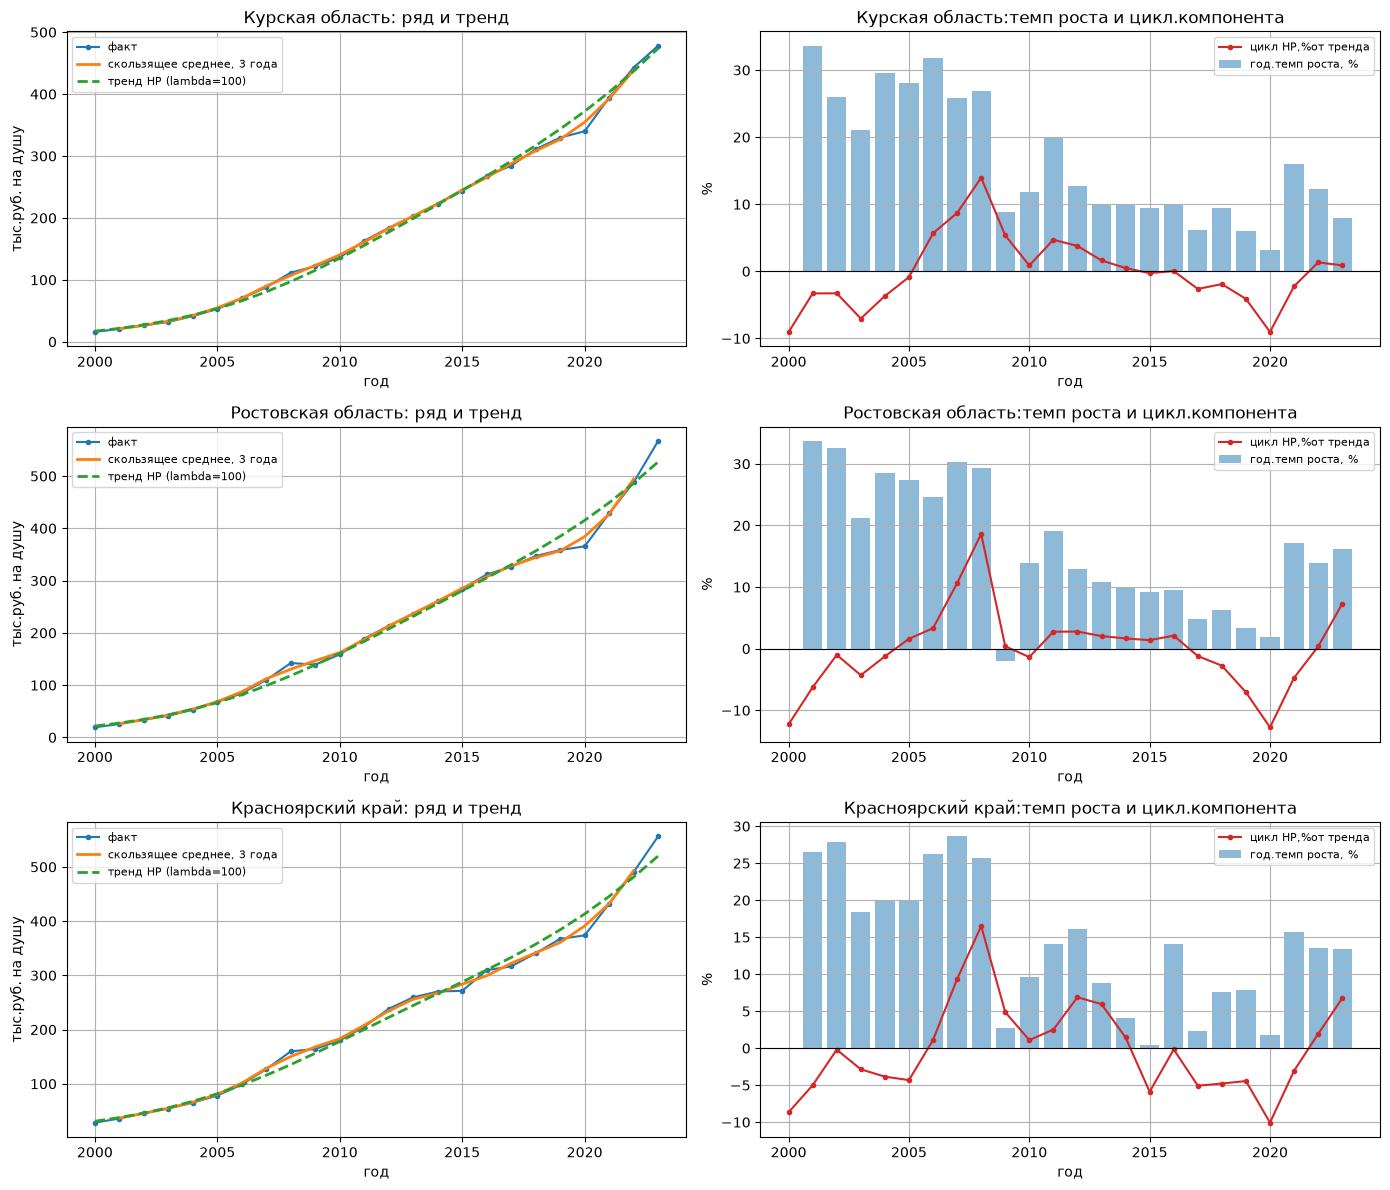

In [52]:
HP_LAMBDA=100
hp={}
fig,axes=plt.subplots(3,2,figsize=(14,12))
for i,r in enumerate(REP_LIST):
    y=series[r]
    t=y.index.year
    cycle,trend=hpfilter(np.log(y),lamb=HP_LAMBDA)
    hp[r]=pd.DataFrame({'trend':np.exp(trend),'cycle_%':cycle*100})
    ax=axes[i,0]
    ax.plot(t,y/1e3,marker='o',ms=3,label='факт')
    ax.plot(t,y.rolling(3,center=True).mean()/1e3,lw=2,label='скользящее среднее, 3 года')
    ax.plot(t,np.exp(trend)/1e3,ls='--',lw=2,label=f'тренд НР (lambda={HP_LAMBDA})')
    ax.set(title=f'{r}: ряд и тренд',xlabel='год',ylabel='тыс.руб. на душу')
    ax.legend(fontsize=8)
    ax=axes[i,1]
    ax.bar(t,y.pct_change()*100,color='C0',alpha=0.5,label='год.темп роста, %')
    ax.plot(t,cycle*100,color='C3',marker='o',ms=3,label='цикл НР,%от тренда')
    ax.axhline(0,color='k',lw=0.8)
    ax.set(title=f'{r}:темп роста и цикл.компонента',xlabel='год',ylabel='%')
    ax.legend(fontsize=8)
plt.tight_layout()
savefig('08_trend_cycle')
plt.show()

In [53]:
#годы с самыми большими отклонениями от НР-тренда
top_cycle={}
for r in REP_LIST:
    c=hp[r]['cycle_%']
    top_cycle[r]=[f'{p.year}: {c[p]:+.1f}%' for p in c.abs().sort_values(ascending=False).index[:5]]
pd.DataFrame(top_cycle,index=[f'#{i}' for i in range(1,6)]).T

,#1,#2,#3,#4,#5
Курская область,2008: +14.0%,2000: -9.1%,2020: -9.0%,2007: +8.7%,2003: -7.0%
Ростовская область,2008: +18.6%,2020: -12.8%,2000: -12.3%,2007: +10.6%,2023: +7.3%
Красноярский край,2008: +16.5%,2020: -10.1%,2007: +9.3%,2000: -8.7%,2012: +6.9%


Тренд у всех трёх сильно выражен и нелинейный: кривая выпуклая, в рублях рост ускоряется. Скользящее среднее за 3 года почти лежит на факте, НР сглаживает сильнее и хорошо показывает, где ряд уходит от тренда. А вот сам темп роста за 23 года сильно менялся: 18-35% в год в 2001-2008, обвал в 2009 (от -2% у Ростова до 9% у Курска), 10-20% в 2010-2013, в основном 2-10% в 2014-2020 и снова 12-17% в 2021-2023.

Циклическая компонента у всех трёх одинаковой формы. Пик в 2008 (+14.0%, +18.6%, +16.5% от тренда) - перегрев перед кризисом, затем провал 2020 (-9.0%, -12.8%, -10.1%) - пандемия. Значения 2000 года (-9..-12%) - это в основном краевой эффект НР-фильтра, на концах ряда он ненадёжен. Сильнее всего колеблется Ростовская область, у неё же единственный год со снижением (2009). У Красноярского края видна своя просадка в 2015, когда рост за год был всего +0.5%, а Курская область самая гладкая.

Сезонной декомпозиции не может быть! Сезонность - это повторяющийся паттерн внутри года (зима/лето или какие-нибудь кварталы), а у нас одна точка на год, внутригодовой структуры в данных просто нет.

### 4.2. Тест Дики-Фуллера

Проверяю четыре варианта ряда: уровень и логарифм (в регр.теста включены константа и тренд, раз ряд явно растёт), первую и вторую разности логарифма (только константа). Разность логарифма - это по сути годовой темп роста. Число лагов подбирается по AIC, но не больше 3: в ряду всего 24 точки, а по умолчанию adfuller берёт до 8 лагов и съедает треть наблюдений.

In [54]:
ADF_MAXLAG=3
ADF_VARIANTS={
    'уровень(c+t)':(lambda y:y,'ct'),
    'log(c+t)':(lambda y:np.log(y),'ct'),
    'd1 log(c)':(lambda y:np.log(y).diff(),'c'),
    'd2 log(c)':(lambda y:np.log(y).diff().diff(),'c'),
}

def adf_table(y):
    rows=[]
    for name,(f,reg) in ADF_VARIANTS.items():
        stat,p,lags,nobs,crit,_=adfuller(f(y).dropna(),maxlag=ADF_MAXLAG,autolag='AIC',regression=reg)
        rows.append({'ряд':name,'ADF':stat,'p-value':p,'лагов':lags,'n':nobs,'крит. 5%':crit['5%'],'стационарен (5%)':p<0.05})
    return pd.DataFrame(rows).set_index('ряд')

adf_res={}
for r in REP_LIST:
    adf_res[r]=adf_table(series[r])
    print(r)
    display(adf_res[r].round(3))

Курская область


,ADF,p-value,лагов,n,крит. 5%,стационарен (5%)
ряд,,,,,,
уровень(c+t),-0.023,0.994,0,23,-3.622,False
log(c+t),-2.243,0.466,0,23,-3.622,False
d1 log(c),-2.116,0.238,0,22,-3.005,False
d2 log(c),-5.899,0.000,0,21,-3.013,True


Ростовская область


,ADF,p-value,лагов,n,крит. 5%,стационарен (5%)
ряд,,,,,,
уровень(c+t),1.151,1.000,0,23,-3.622,False
log(c+t),-2.665,0.251,0,23,-3.622,False
d1 log(c),-2.656,0.082,0,22,-3.005,False
d2 log(c),-5.421,0.000,1,20,-3.022,True


Красноярский край


,ADF,p-value,лагов,n,крит. 5%,стационарен (5%)
ряд,,,,,,
уровень(c+t),0.892,1.000,0,23,-3.622,False
log(c+t),-2.343,0.410,0,23,-3.622,False
d1 log(c),-2.619,0.089,0,22,-3.005,False
d2 log(c),-6.141,0.000,0,21,-3.013,True


In [56]:
#порядок интегрирования для лог.:первая разность, 
# на которой АДФ отвергает единичный корень
def integration_order(tab):
    for d,name in enumerate(['log(c+t)','d1 log(c)','d2 log(c)']):
        if tab.loc[name,'стационарен (5%)']:
            return d
    return 2

D_ORDER={r:integration_order(adf_res[r]) for r in REP_LIST}
D_ORDER

{'Курская область': 2, 'Ростовская область': 2, 'Красноярский край': 2}

В уровнях единичный корень очевиден (р0.99-1.0), в логарифме с трендом тоже (р0.25-0.47) - т.е. ряд не просто "экспонента плюс шум вокруг неё". Первая разность логарифма, то есть годовой темп роста, у Курской области нестационарна (р=0.24), а у Ростова и Красноярска р=0.08-0.09: на 10% мы бы единичный корень отвергли, на 5% - нет. И это по графикам понятно, сам темп роста дрейфует - от 25-30% в начале 2000-х к 5-10% в конце 2010-х. Вторая разность логарифма стационарна у всех (р<0.001).

Поэтому для ARIMA d=2 на логарифме. Оговорка тут есть: в ряду всего 24 точки, мощность ADF при такой длине маленькая, и d=2 может оказаться передифференцированием. Отрицательная автокорреляция на первом лаге во второй разности (ниже,-0.28....-0.34) как раз типичный признак такого, но она в пределах доверительной полосы.

### 4.3. ACF и PACF

Строю ACF/PACF для того ряда, который по ADF получился стационарным (разность логарифма порядка d), до 8 лагов - больше при 22 точках смысла нет, PACF дальше просто шумит.

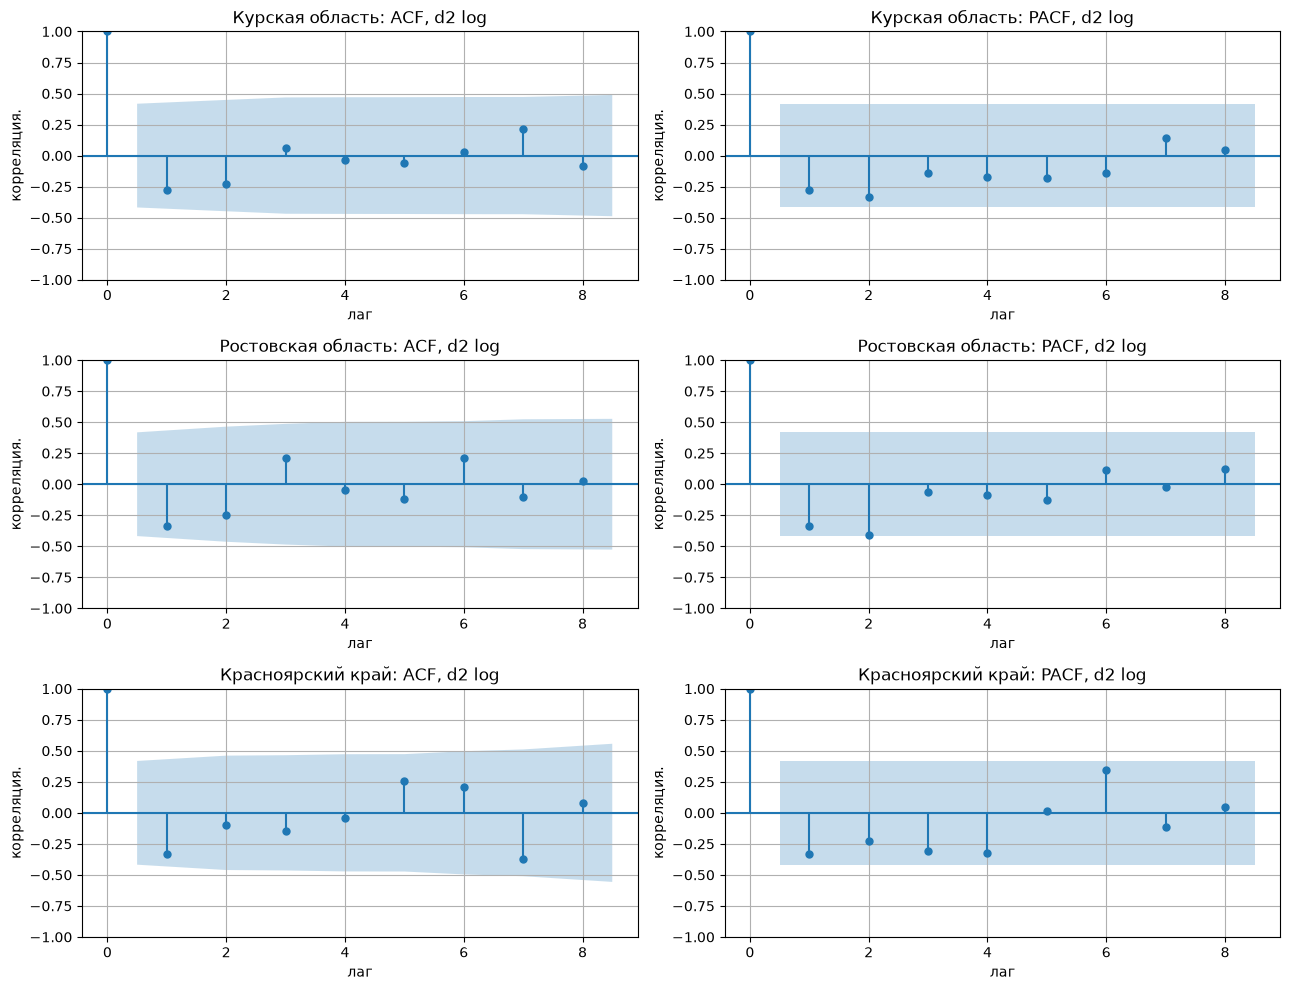

граница значимости ~ +- 0.42


lag 1  lag 2  lag 3  lag 4
Курская область    ACF   -0.28  -0.23   0.06  -0.04
                   PACF  -0.28  -0.33  -0.14  -0.17
Ростовская область ACF   -0.34  -0.25   0.21  -0.04
                   PACF  -0.34  -0.41  -0.06  -0.09
Красноярский край  ACF   -0.33  -0.10  -0.15  -0.04
                   PACF  -0.33  -0.23  -0.31  -0.32

In [59]:
ACF_LAGS=8
fig,axes=plt.subplots(3,2,figsize=(13,10))
acf_tab={}
for i,r in enumerate(REP_LIST):
    d=D_ORDER[r]
    z=np.log(series[r])
    for _ in range(d):
        z=z.diff()
    z=z.dropna()
    plot_acf(z,lags=ACF_LAGS,ax=axes[i,0],title=f'{r}: ACF, d{d} log')
    plot_pacf(z,lags=ACF_LAGS,ax=axes[i,1],title=f'{r}: PACF, d{d} log',method='ywm')
    for ax in axes[i]:
        ax.set(xlabel='лаг',ylabel='корреляция.')
    acf_tab[(r,'ACF')]=acf(z,nlags=4)[1:]
    acf_tab[(r,'PACF')]=pacf(z,nlags=4,method='ywm')[1:]
plt.tight_layout()
savefig('09_acf_pacf')
plt.show()
print('граница значимости ~ +-',round(1.96/np.sqrt(len(z)),2))
pd.DataFrame(acf_tab,index=[f'lag {i}' for i in range(1,5)]).T.round(2)

Все значения ACF и PACF у трёх регионов лежат внутри полосы +-0.42, то есть формально вторая разность логарифма - это белый шум. Отсюда базовая гипотеза ARIMA(0,2,0): темп роста ведёт себя как случайное блуждание, прогноз = "последний темп роста сохранится".

Но ACF на первом лаге у всех отрицательный (-0.28..-0.34) и дальше быстро затухает, а это картинка MA(1) с отрицательным коэффициентом - поэтому вторая гипотеза ARIMA(0,2,1). У Рост.обл. PACF на втором лаге -0.41, почти на границе, так что для неё ещё вариант (2,2,0). У Красн.края PACF на лагах 3-4 около -0.32, но при 21 точке я бы на это не опирался. 

Итого жду p, q от 0 до 1, максимум 2. И ещё одно: ARIMA(0,2,1)-(0,2,2) теоретически очень близка к линейному Holt, так что на прогнозе Holt и ARIMA, скорее всего, разойдутся несильно.

### 4.4. Сравнение регионов

In [66]:
comp=pd.DataFrame({r:{
    'кластер':feats.loc[r,'cluster_name'],
    ' тыс.руб/год':stats.loc[r,'наклон,тыс.руб/год'],
    'CAGR, %':feats.loc[r,'cagr']*100,
    'CV':feats.loc[r,'cv'],
    'std темпа роста, п.п.':series[r].pct_change().std()*100,
    'max_drop, %':feats.loc[r,'max_drop']*100,
    'std цикла HP, %':hp[r]['cycle_%'].std(),
    'ADF p(d1 log)':adf_res[r].loc['d1 log(c)','p-value'],
    'ADF p(d2 log)':adf_res[r].loc['d2 log(c)','p-value'],
    'd':D_ORDER[r],
    'ACF lag1':acf_tab[(r,'ACF')][0],
} for r in REP_LIST}).T
num_cols=comp.columns.drop('кластер')
comp[num_cols]=comp[num_cols].astype(float).round(3)
comp['d']=comp['d'].astype(int)
comp

,кластер,тыс.руб/год,"CAGR, %",CV,"std темпа роста, п.п.","max_drop, %","std цикла HP, %",ADF p(d1 log),ADF p(d2 log),d,ACF lag1
Курская область,A: устойчивый быстрый рост,19.576,16.015,0.737,9.442,3.114,5.338,0.238,0.0,2,-0.276
Ростовская область,B:рост с просадками,21.679,15.843,0.714,10.525,-2.038,6.634,0.082,0.0,2,-0.340
Красноярский край,"C:высокий старт, медленный рост",20.879,13.807,0.659,8.960,0.494,6.189,0.089,0.0,2,-0.329


В рублях тренд круче всего у Ростовской области (21.7 тыс.руб. в год), но в процентах быстрее всех росла Курская(cagr 16.0%), а медленнее Красноярский край(13.8%) - он стартовал выше и растёт с большей базы. По волатильности лидирует Ростов:самый большой разброс темпа роста (10.5 п.п.) и цикла HP (6.6%), и только у него есть год со снижением. У Красноярского края разброс темпа наименьший (9.0 п.п.), но цикл всё равно заметный (6.2%) - колебания у него более затяжные, через 2015 и 2020. Курская область самая ровная (цикл 5.3%).

По стационарности все три одинаковые: нестационарны в уровнях, логарифмах и первых разностях на 5%, стационарны во вторых разностях логарифма. Разница только в том, что у Ростова и Красноярска темп роста ближе к стационарному (p около 0.08-0.09 против 0.24 у Курска), то есть темп у них чаще возвращается к среднему после всплесков. ACF и PACF по форме похожи, отличия в деталях - лаг 2 у Ростова и лаги 3-4 у Красноярска.

## Этап 5. Прогнозирование

### 5.1. Разбиение и модели

Горизонт - 5 лет, одинаковый для всех регионов. Тест - последние 5 лет (2019-2023), train - 2000-2018, это 19 из 24 точек, 79%. Тот же горизонт 5 лет беру и для прогноза в будущее (2024-2028).
Модели:
- Naive - NaiveForecaster(strategy="last") из sktime, бейзлайн;
- Holt - экспоненциальное сглаживание с аддитивным трендом;
- ARIMA(p, d, q) - d берётся из теста Дики-Фуллера (этап 4), p и q от 0 до 2 подбираются по AIC только на train.

Holt и ARIMA обучаются на логарифме ряда, прогноз потом возвращается через exp. Ряд в текущих ценах растёт почти по экспоненте, и в логарифме линейный тренд Holt означает постоянный темп роста, а не постоянный прирост в рублях - для инфляционного ряда это естественнее. Метрики считаются уже в рублях.

In [67]:
H=5

def split(y,h=H):
    return y.iloc[:-h],y.iloc[-h:]

tr,te=split(series[REP_LIST[0]])
print(f'train: {tr.index[0]}-{tr.index[-1]} ({len(tr)} точек, {len(tr)/(len(tr)+len(te))*100:.0f}%) | test: {te.index[0]}-{te.index[-1]} ({len(te)})')

train: 2000-2018 (19 точек, 79%) | test: 2019-2023 (5)


In [68]:
def arima_trend(d):
    # при d=1 нужен дрейф (ср.темп роста), при d=2 константа уже не нужна
    return {0:'ct',1:'t'}.get(d,'n')

def select_arima(y_tr,d,max_p=2,max_q=2):
    # перебор p,q по AIC на train; d фиксирован по ADF
    rows=[]
    for p in range(max_p+1):
        for q in range(max_q+1):
            try:
                m=ARIMA(np.log(y_tr),order=(p,d,q),trend=arima_trend(d)).fit()
                rows.append({'order':(p,d,q),'AIC':m.aic})
            except Exception:
                pass
    tab=pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
    return tab.loc[0,'order'],tab

def forecast(model,y_tr,h,order=None):
    #обищий интерфейс:обучить на y_tr, вернуть прогноз на h шагов(np.array,в руб.)
    if model=='Naive':
        f=NaiveForecaster(strategy='last').fit(y_tr).predict(fh=np.arange(1,h+1))
        return np.asarray(f,dtype=float)
    if model=='Holt':
        m=ExponentialSmoothing(np.log(y_tr),trend='add',initialization_method='estimated').fit()
        return np.exp(np.asarray(m.forecast(h)))
    if model=='ARIMA':
        m=ARIMA(np.log(y_tr),order=order,trend=arima_trend(order[1])).fit()
        return np.exp(np.asarray(m.forecast(h)))
    raise ValueError(model)

MODELS=['Naive','Holt','ARIMA']

In [69]:
ARIMA_ORDER={}
for r in REP_LIST:
    tr,_=split(series[r])
    ARIMA_ORDER[r],tab=select_arima(tr,D_ORDER[r])
    print(r,'-> лучший порядок',ARIMA_ORDER[r])
    display(tab.head(5).round(2))

Курская область -> лучший порядок (0, 2, 0)


,order,AIC
0,"(0, 2, 0)",-49.47
1,"(0, 2, 1)",-48.91
2,"(1, 2, 0)",-48.36
3,"(2, 2, 0)",-47.21
4,"(0, 2, 2)",-47.11


Ростовская область -> лучший порядок (0, 2, 1)


,order,AIC
0,"(0, 2, 1)",-36.16
1,"(2, 2, 0)",-35.68
2,"(0, 2, 2)",-34.19
3,"(1, 2, 1)",-34.17
4,"(2, 2, 1)",-33.81


Красноярский край -> лучший порядок (0, 2, 1)


,order,AIC
0,"(0, 2, 1)",-39.00
1,"(0, 2, 0)",-38.09
2,"(1, 2, 0)",-37.51
3,"(0, 2, 2)",-37.42
4,"(1, 2, 1)",-37.34


Автоподбор по AIC подтвердил гипотезы с этапа 4. Для Курской обл. лучшей вышла ARIMA(0,2,0) - чистый белый шум во второй разности, ровно базовая гипотеза. 

Для Ростова и Красноярска - ARIMA(0,2,1), вторая гипотеза с отрицательным MA(1). Разрыв по AIC с соседними вариантами маленький (0.5-0.9), при 19 точках AIC их толком не различает, но все топовые варианты лежат в ожидаемом диапазоне p, q от 0 до 2.

### 5.2. Прогноз на тесте и метрики

In [70]:
fc_test={}
rows=[]
for r in REP_LIST:
    tr,te=split(series[r])
    for m in MODELS:
        f=forecast(m,tr,H,ARIMA_ORDER[r])
        fc_test[(r,m)]=pd.Series(f,index=te.index)
        rows.append({'регион':r,'модель':m if m!='ARIMA' else f'ARIMA{ARIMA_ORDER[r]}',
                     'rmse, руб':root_mean_squared_error(te,f),
                     'mape, %':mean_absolute_percentage_error(te,f)*100})
metrics=pd.DataFrame(rows)

# лучшая модель по рмсе на тесте
BEST={r:MODELS[int(np.argmin(metrics.loc[metrics['регион']==r,'rmse, руб'].values))] for r in REP_LIST}
metrics['лучшая']=[BEST[r]==(m.split('(')[0]) for r,m in zip(metrics['регион'],metrics['модель'])]
display(metrics.round(1))
BEST

,регион,модель,"rmse, руб","mape, %",лучшая
0,Курская область,Naive,103408.4,20.0,False
1,Курская область,Holt,13883.0,3.0,True
2,Курская область,"ARIMA(0, 2, 0)",16605.3,3.6,False
3,Ростовская область,Naive,122815.8,19.0,False
4,Ростовская область,Holt,39595.8,6.5,True
5,Ростовская область,"ARIMA(0, 2, 1)",41102.1,6.7,False
6,Красноярский край,Naive,125730.9,21.3,False
7,Красноярский край,Holt,45370.1,6.9,True
8,Красноярский край,"ARIMA(0, 2, 1)",46015.0,7.0,False


{'Курская область': 'Holt',
 'Ростовская область': 'Holt',
 'Красноярский край': 'Holt'}

In [71]:
#ошибки по годам теста: где именно модели расходятся с фактом
err_rows=[]
for r in REP_LIST:
    te=split(series[r])[1]
    for m in MODELS:
        e=(te-fc_test[(r,m)])/te*100
        err_rows.append(pd.Series(e.values,index=te.index.year,name=(r,m)))
pd.DataFrame(err_rows).round(1)

year                      2019  2020  2021  2022  2023
Курская область    Naive   5.7   8.5  21.1  29.8  34.9
                   Holt   -2.5  -8.0  -1.2   2.1   1.4
                   ARIMA  -3.2  -9.4  -3.2  -0.5  -1.9
Ростовская область Naive   3.2   5.1  19.0  28.9  38.8
                   Holt   -3.8  -9.1   0.2   6.1  13.3
                   ARIMA  -3.6  -8.8   0.6   6.6  13.9
Красноярский край  Naive   7.2   8.8  21.1  30.5  38.7
                   Holt    1.0  -3.8   4.3  10.0  15.4
                   ARIMA   1.1  -3.7   4.4  10.2  15.6

In [73]:
#проверка решения про логарифм - тот же Holt, но на уровнях ряда
lvl=[]
for r in REP_LIST:
    tr,te=split(series[r])
    f=ExponentialSmoothing(tr,trend='add',initialization_method='estimated').fit().forecast(H)
    lvl.append({'регион':r,'holt на уровнях, mape %':mean_absolute_percentage_error(te,f)*100,
                'Holt на логарифме, mape %':metrics.loc[(metrics['регион']==r)&(metrics['модель']=='Holt'),'mape, %'].iloc[0]})
pd.DataFrame(lvl).set_index('регион').round(1)

,"holt на уровнях, mape %","Holt на логарифме, mape %"
регион,,
Курская область,6.0,3.0
Ростовская область,9.9,6.5
Красноярский край,10.2,6.9


Наивный прогноз проваливается везде: mape 19-21%, к 2023 году "замороженное" значение 2018 отстаёт от факта на 35-39%. Ряд растёт, так что бейзлайн тут слабый, но обе статист.модели обыгрывают его в 3-7 раз по rmse, значит прогнозы содержательные.

Holt лучший во всех трёх регионах: mape 3.0% у Курска, 6.5% у Ростова, 6.9% у Красноярска. ARIMA отстаёт совсем чуть-чуть (3.6, 6.7, 7.0%) - как и ожидалось, arima(0,2,1) по сути та же модель локального линейного тренда.

По годам картина у моделей одинаковая. В 2019-2020 они переоценивают (в 2020 до -8..-9% у Курска и Ростова), тут пандемия. С 2021 у Ростова и Красноярска пошла недооценка, к 2023 уже +13.3% и +15.4%: в 2021-2023 рост номинального потребления ускорился до 13-17% в год, а train (2000-2018) заканчивается на замедлении, и модели этого разгона знать не могли. Курская область тут исключение, у неё 2022-2023 были спокойнее (12.3% и 7.9%), и ошибка к 2023 всего +1.4%.

Заодно проверил решение про логарифм: тот же Holt на уровнях даёт mape 6.0%, 9.9% и 10.2% против 3.0%, 6.5% и 6.9% на логарифме, так что переход к логарифму себя оправдал.

### 5.3. Устойчивость: expanding window

expanding window: для каждого года t с 2009 по 2023 лучшая модель региона обучается на всех данных 2000..t-1 и прогнозирует один шаг вперёд. Обучающая выборка растёт с 9 до 23 точек, а набор прогнозируемых лет фиксирован. По сравнению с rolling здесь не выбрасываются старые наблюдения - при 24 точках это важно, окно фиксированной длины было бы совсем коротким. 2009 как старт выбран, чтобы в оценку попал кризис 2008-2009. Порядок ARIMA держу тем, что выбран на train, переобучаются только коэффициенты.

In [74]:
EXP_START=2009

def expanding_one_step(y,model,order=None,start=EXP_START):
    rows=[]
    for t in range(start,y.index.year[-1]+1):
        tr=y[y.index.year<t]
        f=forecast(model,tr,1,order)[0]
        actual=y[y.index.year==t].iloc[0]
        rows.append({'year':t,'train_size':len(tr),'actual':actual,'forecast':f})
    d=pd.DataFrame(rows).set_index('year')
    d['error']=d['actual']-d['forecast']
    d['error_%']=d['error']/d['actual']*100
    return d

exp_res={r:expanding_one_step(series[r],BEST[r],ARIMA_ORDER[r]) for r in REP_LIST}
exp_res[REP_LIST[0]].round(1)

,train_size,actual,forecast,error,error_%
year,,,,,
2009,9,121783.8,142597.3,-20813.5,-17.1
2010,10,136200.2,170808.8,-34608.6,-25.4
2011,11,163201.7,150822.0,12379.7,7.6
2012,12,184039.6,191256.1,-7216.5,-3.9
2013,13,202499.7,211086.1,-8586.4,-4.2
2014,14,222793.9,226411.3,-3617.4,-1.6
2015,15,243871.2,246504.9,-2633.7,-1.1
2016,16,267964.8,267965.4,-0.6,-0.0
2017,17,284312.4,294439.0,-10126.6,-3.6


In [79]:
def rmse_mape(d):
    return root_mean_squared_error(d['actual'],d['forecast']),d['error_%'].abs().mean()

rows=[]
for r in REP_LIST:
    d=exp_res[r]
    fixed=metrics[(metrics['регион']==r)&metrics['лучшая']].iloc[0]
    row={'регион':r,'модель':BEST[r],
         'fixed split 2019-2023: RMSE':fixed['rmse, руб'],'fixed: MAPE, %':fixed['mape, %']}
    rm,mp=rmse_mape(d.loc[2019:2023])
    row.update({'expanding 2019-2023: RMSE':rm,'expanding 2019-2023: MAPE, %':mp})
    for a,b in [(2009,2013),(2014,2018),(2019,2023)]:
        row[f'MAPE {a}-{b}, %']=d.loc[a:b,'error_%'].abs().mean()
    rm,mp=rmse_mape(d)
    row.update({'expanding 2009-2023: MAPE, %':mp})
    rows.append(row)
robust=pd.DataFrame(rows).set_index('регион')
robust.round(1).T

регион,Курская область,Ростовская область,Красноярский край
модель,Holt,Holt,Holt
fixed split 2019-2023: RMSE,13883.0,39595.8,45370.1
"fixed: MAPE, %",3.0,6.5,6.9
expanding 2019-2023: RMSE,20422.2,27241.1,22730.2
"expanding 2019-2023: MAPE, %",4.2,5.4,4.4
"MAPE 2009-2013, %",11.6,14.4,11.4
"MAPE 2014-2018, %",1.6,2.8,6.8
"MAPE 2019-2023, %",4.2,5.4,4.4
"expanding 2009-2023: MAPE, %",5.8,7.6,7.5


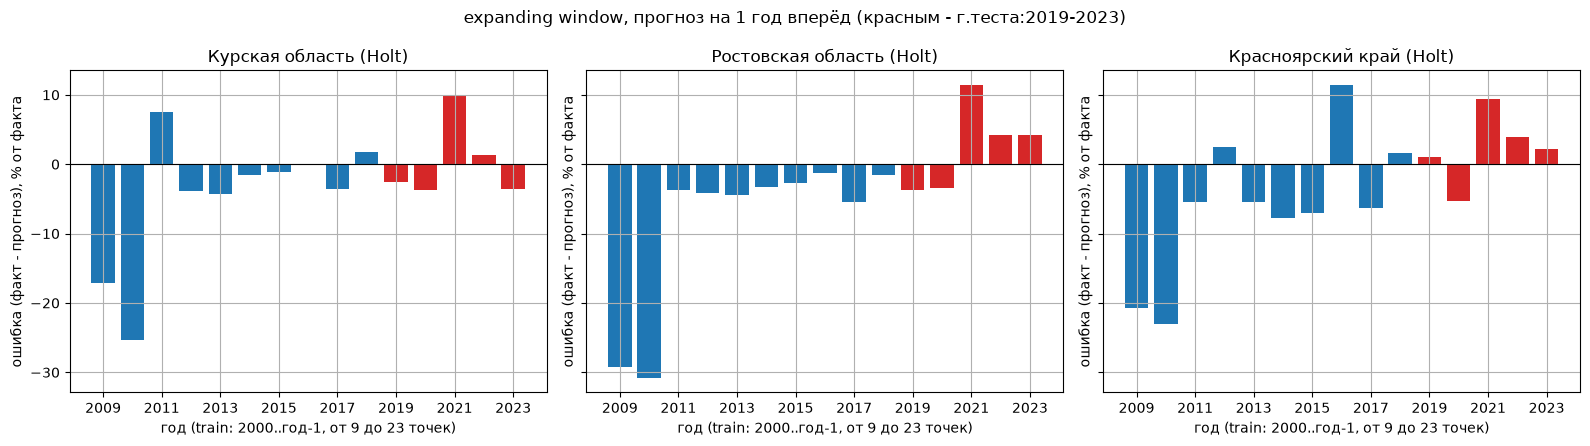

In [81]:
fig,axes=plt.subplots(1,3,figsize=(16,4.5),sharey=True)
for ax,r in zip(axes,REP_LIST):
    d=exp_res[r]
    colors=['C3' if y>=2019 else 'C0' for y in d.index]
    ax.bar(d.index,d['error_%'],color=colors)
    ax.axhline(0,color='k',lw=0.8)
    ax.set(title=f'{r} ({BEST[r]})',xlabel='год (train: 2000..год-1, от 9 до 23 точек)',ylabel='ошибка (факт - прогноз), % от факта')
    ax.set_xticks(range(EXP_START,2024,2))
fig.suptitle('expanding window, прогноз на 1 год вперёд (красным - г.теста:2019-2023)')
plt.tight_layout()
savefig('10_expanding')
plt.show()

На тех же годах 2019-2023 одношаговый прогноз с переобучением даёт МАРЕ 4.2%, 5.4% и 4.4% против 3.0%, 6.5% и 6.9% на фиксированном разбиении. Для Ростова и Красноярска обновление данных заметно помогает - модель каждый год подхватывает свежий темп и разгон 2021-2023 уже не пропускает. У Курска наоборот чуть хуже, но там фиксированному прогнозу скорее повезло: ошибки разных знаков компенсировали друг друга, а одношаговый прогноз из провала 2020 честно промахнулся в 2021 (+9.9%).

Если смотреть по периодам, видно, как ошибка зависит от накопленных данных. В 2009-2013 МАРЕ 11-14% - в train всего 9-13 точек, и на них пришёлся кризис. В 2014-2018 уже 1.6-2.8% у Курска и Ростова (6.8% у Красноярска, у него 2015-2016 качнуло). В 2019-2023 4-5%. То есть примерно после 14-15 лет истории модель стабилизируется, а дальше ошибка определяется уже шоками, а не длиной ряда. В целом прогноз устойчивый: на последних годах одношаговая ошибка не растёт, и Holt остаётся рабочей моделью при обновлении данных.

### 5.4. Прогноз на 2024-2028 и графики

Для прогноза в будущее модели переобучаются на всём ряде 2000-2023 (порядок ARIMA тот же).

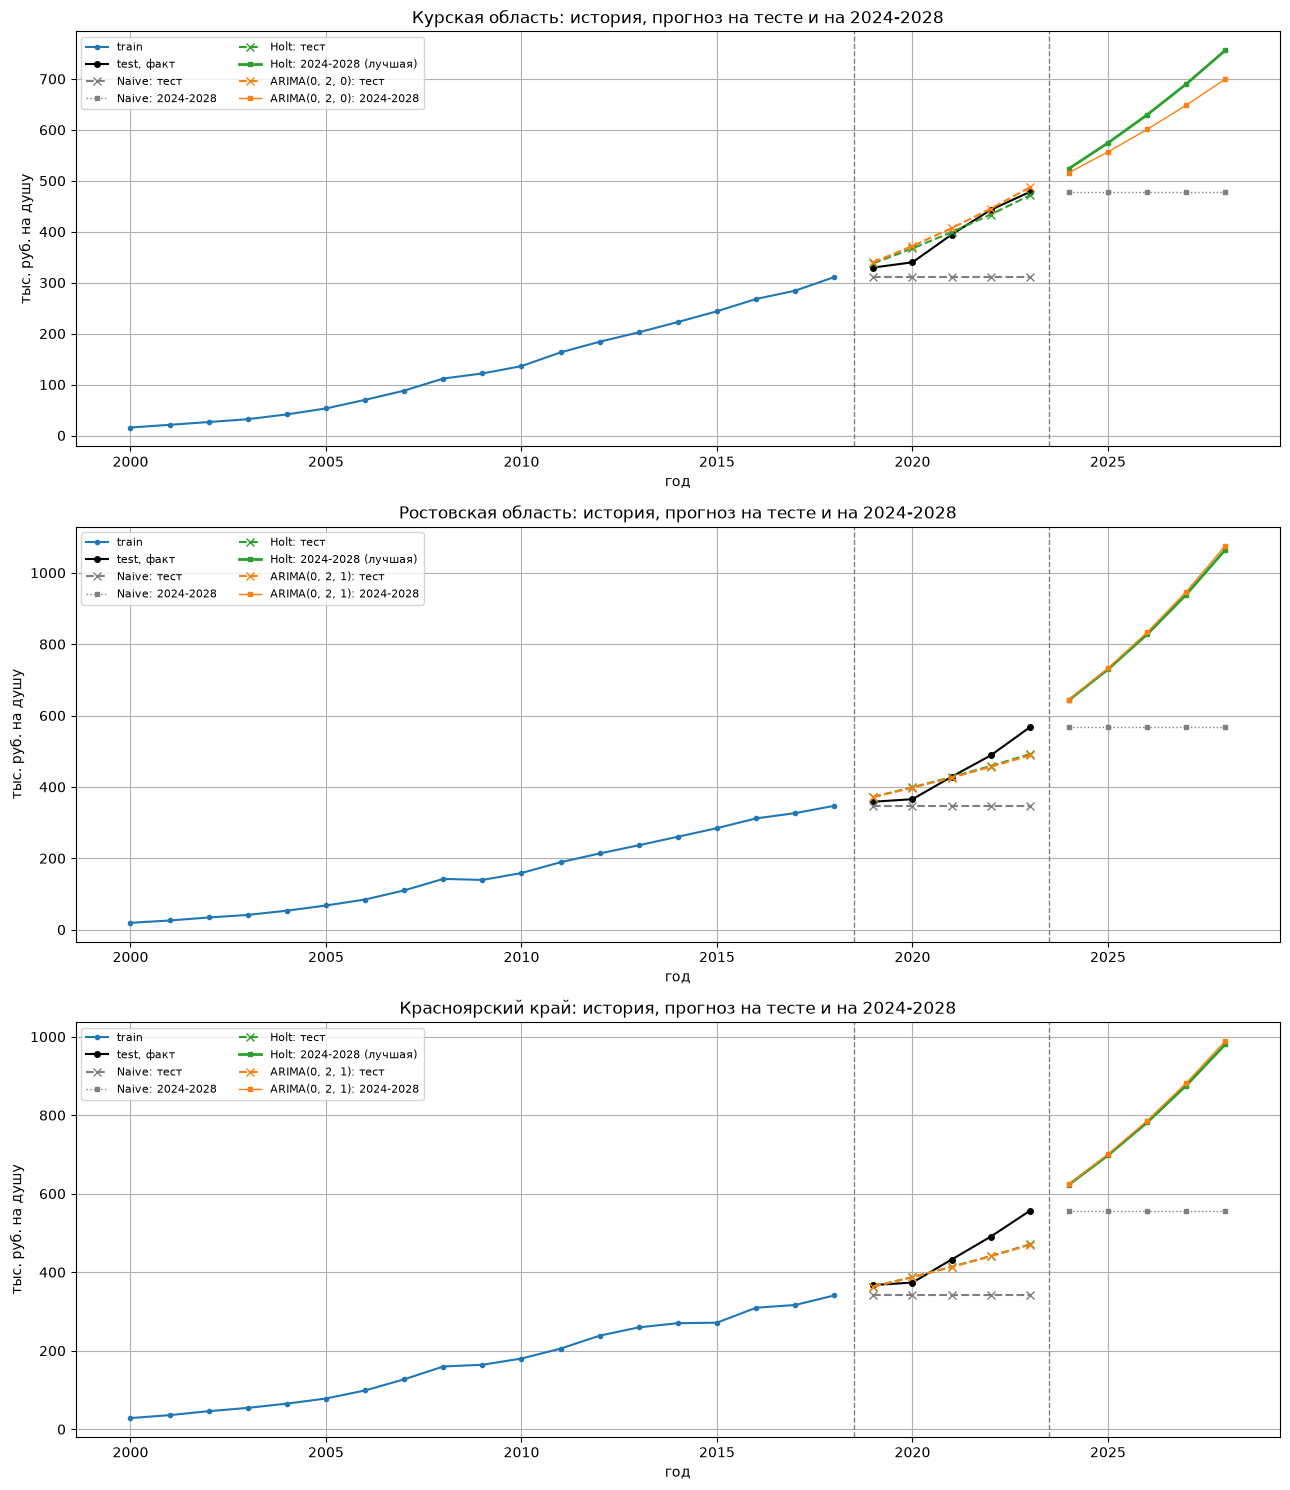

In [82]:
fc_future={}
for r in REP_LIST:
    y=series[r]
    idx=pd.period_range(y.index[-1]+1,periods=H,freq='Y')
    for m in MODELS:
        fc_future[(r,m)]=pd.Series(forecast(m,y,H,ARIMA_ORDER[r]),index=idx)

fig,axes=plt.subplots(3,1,figsize=(13,15))
styles={'Naive':('C7',':'),'Holt':('C2','-'),'ARIMA':('C1','-')}
for ax,r in zip(axes,REP_LIST):
    y=series[r]
    tr,te=split(y)
    ax.plot(tr.index.year,tr/1e3,color='C0',marker='o',ms=3,label='train')
    ax.plot(te.index.year,te/1e3,color='k',marker='o',ms=4,label='test, факт')
    for m in MODELS:
        c,ls=styles[m]
        lbl=m if m!='ARIMA' else f'ARIMA{ARIMA_ORDER[r]}'
        ax.plot(te.index.year,fc_test[(r,m)]/1e3,color=c,ls='--',marker='x',label=f'{lbl}: тест')
        ax.plot(fc_future[(r,m)].index.year,fc_future[(r,m)]/1e3,color=c,ls=ls,lw=2 if m==BEST[r] else 1,marker='s',ms=3,label=f'{lbl}: 2024-2028'+(' (лучшая)' if m==BEST[r] else ''))
    ax.axvline(te.index.year[0]-0.5,color='gray',ls='--',lw=1)
    ax.axvline(y.index.year[-1]+0.5,color='gray',ls='--',lw=1)
    ax.set(title=f'{r}: история, прогноз на тесте и на 2024-2028',xlabel='год',ylabel='тыс. руб. на душу')
    ax.legend(fontsize=8,ncol=2,loc='upper left')
plt.tight_layout()
savefig('11_forecasts')
plt.show()

In [83]:
fut=pd.DataFrame({(r,m if m!='ARIMA' else f'ARIMA{ARIMA_ORDER[r]}'):fc_future[(r,m)].values/1e3 for r in REP_LIST for m in MODELS},index=fc_future[(REP_LIST[0],'Holt')].index.year).T
fut.insert(0,'2023 факт',[series[r].iloc[-1]/1e3 for r,_ in fut.index])
fut['темп 2024-2028, %/год']=((fut[2028]/fut['2023 факт'])**(1/H)-1)*100
fut.round(1)

2023 факт   2024   2025   2026   2027    2028  темп 2024-2028, %/год
Курская область    Naive               478.0  478.0  478.0  478.0  478.0   478.0                    0.0
                   Holt                478.0  523.9  574.3  629.4  689.9   756.1                    9.6
                   ARIMA(0, 2, 0)      478.0  515.9  556.7  600.8  648.3   699.7                    7.9
Ростовская область Naive               567.0  567.0  567.0  567.0  567.0   567.0                    0.0
                   Holt                567.0  643.2  729.6  827.6  938.7  1064.8                   13.4
                   ARIMA(0, 2, 1)      567.0  644.6  732.7  832.9  946.7  1076.2                   13.7
Красноярский край  Naive               556.3  556.3  556.3  556.3  556.3   556.3                    0.0
                   Holt                556.3  623.1  697.9  781.7  875.5   980.5                   12.0
                   ARIMA(0, 2, 1)      556.3  624.2  700.4  785.8  881.7   989.3                   12.2

### 5.5. Лучшая модель по регионам

Во всех трёх регионах лучшая модель - holt на логарифме, хотя отрыв от arima минимальный. Объяснение простое: ряды - гладкий тренд, наклон которого(темп роста) меняется медленно и без сезонности. Holt как раз и моделирует уровень+наклон, оба обновляются по свежим данным. На train у всех трёх alpha=1, то есть уровень просто равен последнему значению, а beta 0.42-0.62 - темп роста подстраивается под последние годы довольно быстро (параметры в таблице на этапе 6). В логарифме это значит "продолжаем текущий темп, плавно его обновляя". ARIMA(0,2,1) математически почти то же самое, отсюда и почти те же цифры. ARIMA(0,2,0) у Курска - это "темп последнего года", он шумнее, отсюда чуть больше ошибка.

Типы регионов на выбор модели не повлияли, а вот на точность - да. Ровный кластер А(Курск) прогнозируется лучше всего (3.0%), кластеры В и С хуже (6.5-6.9%), потому что там в тесте случился разгон, который по прошлому не виден.

Прогноз на 2024-2028 продолжает темп последних лет. По Holt к 2028 Курская область выходит на 756 тыс. руб. (9.6% в год), Ростовская на 1065 тыс. (13.4%), Красноярский край на 980 тыс. (12.0%). Это скорее верхний сценарий: Holt с alpha=1 переносит в будущее разгон 2021-2023, у Ростова 13.4% в год выше даже его фактических 10.3% за 2019-2023. ARIMA(0,2,0) у Курска даёт более осторожные 700 тыс. (7.9% в год).

## Этап 6. Анализ ошибок

Беру ошибки лучшей модели каждого региона из expanding window (прогноз на 1 год, 2009-2023). Так в разбор попадают 15 лет с кризисами 2009, 2014-2015, 2020 и 2022, а не только 5 лет теста - иначе "топ-5" совпал бы со всем тестом. Сортирую по модулю ошибки в процентах.

In [85]:
#быстрый гугл, чтобы точнее узнать проблемы по годам
EVENTS={
    2009:'мировой финансовый кризис 2008-2009',
    2010:'восстановление после кризиса 2009',
    2014:'падение цен на нефть, санкции, девальвация рубля в конце года',
    2015:'спад после девальвации 2014, падение реальных доходов',
    2016:'стагнация доходов после 2015',
    2019:'замедление роста, повышение НДС',
    2020:'пандемия ковида, ограничения',
    2021:'восстановление после ковида, ускорение инфляции',
    2022:'санкции 2022, скачок цен',
    2023:'рост зарплат и кредитования,ускорение инфляции',
}
# почему 2009-2010 так плохо: какие параметры Holt выбирает на коротком и на длинном train
def holt_params(y_tr):
    m=ExponentialSmoothing(np.log(y_tr),trend='add',initialization_method='estimated').fit()
    return f"alpha={m.params['smoothing_level']:.2f}, beta={m.params['smoothing_trend']:.2f}, темп={np.exp(m.trend.iloc[-1])*100-100:.1f}%"

display(pd.DataFrame({r:{f'train 2000-{e}':holt_params(series[r][series[r].index.year<=e]) for e in [2008,2009,2018,2023]} for r in REP_LIST}).T)

top_rows=[]
for r in REP_LIST:
    d=exp_res[r].copy()
    d['abs_%']=d['error_%'].abs()
    top=d.sort_values('abs_%',ascending=False).head(5)
    for yr,row in top.iterrows():
        top_rows.append({'регион':r,'модель':BEST[r],'год':yr,'факт, тыс.руб':row['actual']/1e3,'прогноз, тыс.руб':row['forecast']/1e3,
                         'ошибка, %':row['error_%'],'тип':'недооценка' if row['error']>0 else 'переоценка','событие':EVENTS.get(yr,'')})
top5=pd.DataFrame(top_rows)
top5.round(1)

,train 2000-2008,train 2000-2009,train 2000-2018,train 2000-2023
Курская область,"alpha=0.00, beta=0.00, темп=27.6%","alpha=0.00, beta=0.00, темп=26.5%","alpha=1.00, beta=0.62, темп=8.7%","alpha=1.00, beta=0.54, темп=9.6%"
Ростовская область,"alpha=0.00, beta=0.00, темп=27.7%","alpha=0.00, beta=0.00, темп=25.9%","alpha=1.00, beta=0.42, темп=7.2%","alpha=1.00, beta=0.43, темп=13.4%"
Красноярский край,"alpha=1.00, beta=0.00, темп=24.1%","alpha=0.00, beta=0.00, темп=22.4%","alpha=1.00, beta=0.43, темп=6.7%","alpha=1.00, beta=0.42, темп=12.0%"


,регион,модель,год,"факт, тыс.руб","прогноз, тыс.руб","ошибка, %",тип,событие
0,Курская область,Holt,2010,136.2,170.8,-25.4,переоценка,восстановление после кризиса 2009
1,Курская область,Holt,2009,121.8,142.6,-17.1,переоценка,мировой финансовый кризис 2008-2009
2,Курская область,Holt,2021,394.4,355.2,9.9,недооценка,"восстановление после ковида, ускорение инфляции"
3,Курская область,Holt,2011,163.2,150.8,7.6,недооценка,
4,Курская область,Holt,2013,202.5,211.1,-4.2,переоценка,
5,Ростовская область,Holt,2010,158.7,207.6,-30.8,переоценка,восстановление после кризиса 2009
6,Ростовская область,Holt,2009,139.4,180.1,-29.2,переоценка,мировой финансовый кризис 2008-2009
7,Ростовская область,Holt,2021,428.5,379.7,11.4,недооценка,"восстановление после ковида, ускорение инфляции"
8,Ростовская область,Holt,2017,326.5,344.1,-5.4,переоценка,
9,Ростовская область,Holt,2013,236.6,247.0,-4.4,переоценка,


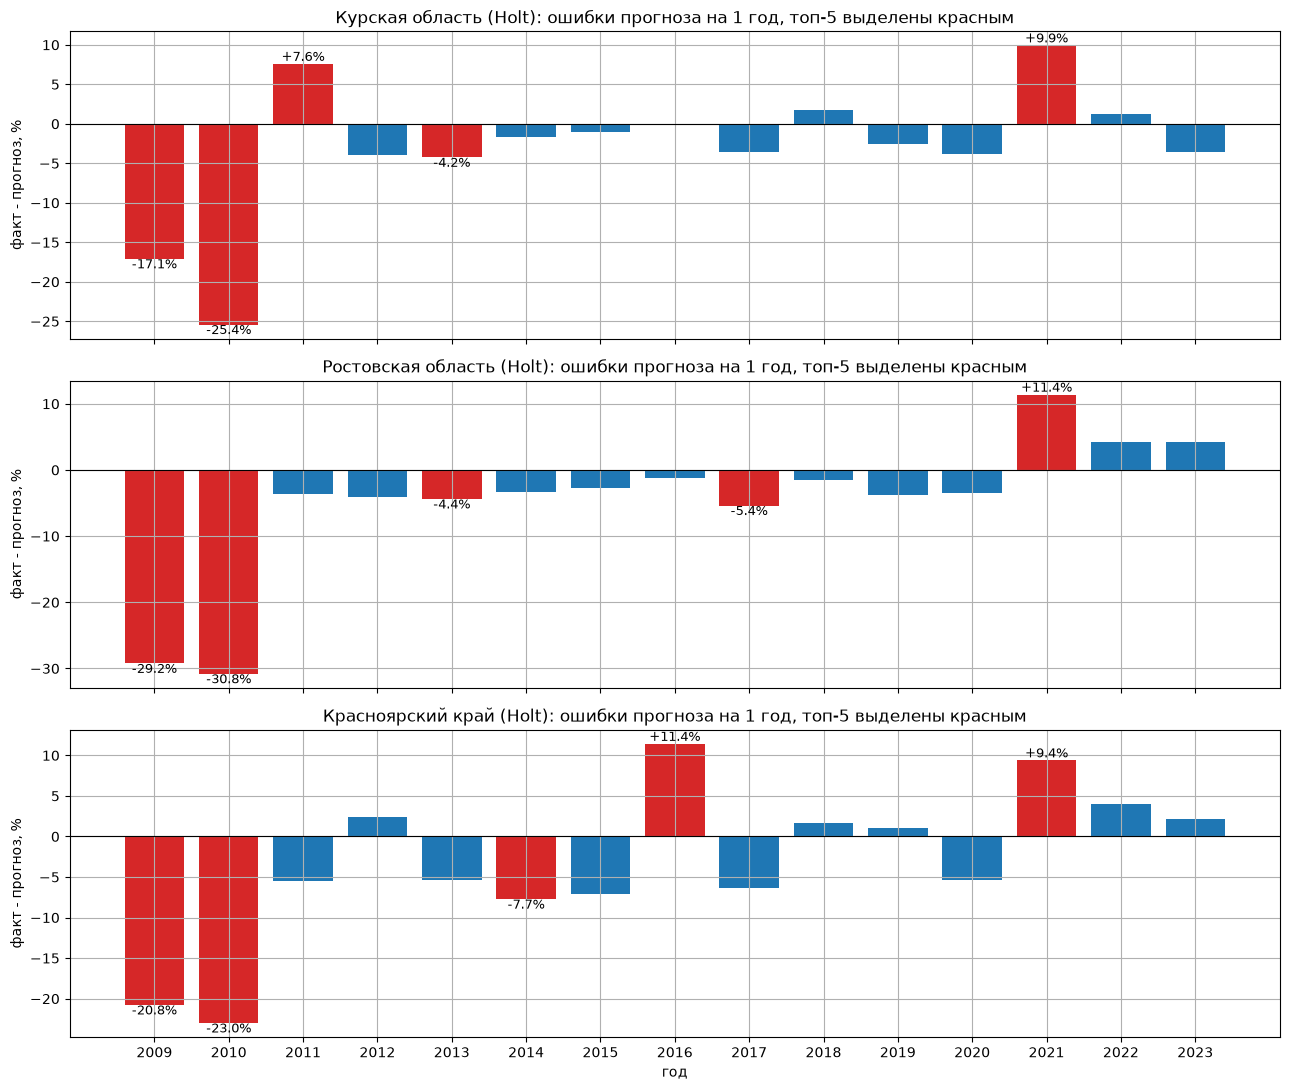

In [86]:
fig,axes=plt.subplots(3,1,figsize=(13,11),sharex=True)
for ax,r in zip(axes,REP_LIST):
    d=exp_res[r]
    top_years=top5.loc[top5['регион']==r,'год'].values
    colors=['C3' if y in top_years else 'C0' for y in d.index]
    ax.bar(d.index,d['error_%'],color=colors)
    ax.axhline(0,color='k',lw=0.8)
    for y in top_years:
        v=d.loc[y,'error_%']
        ax.annotate(f'{v:+.1f}%',(y,v),ha='center',va='bottom' if v>0 else 'top',fontsize=9)
    ax.set(title=f'{r} ({BEST[r]}): ошибки прогноза на 1 год, топ-5 выделены красным',ylabel='факт - прогноз, %')
axes[-1].set_xlabel('год')
axes[-1].set_xticks(range(EXP_START,2024))
plt.tight_layout()
savefig('12_top_errors')
plt.show()

Самые большие промахи у всех трёх регионов - 2009 и 2010, и это переоценка на 17-30.8%. Причина тут не только в кризисе. Таблица выше показывает, что на 9-10 точках оптимизатор Holt выставил beta=0 и почти везде alpha=0, то есть модель выродилась в жёсткую прямую по логарифму, натянутую на бум 2000-2008 (22-28% роста в год). Кризис 2009 обрушил темп до 9% у Курска и до -2% у Ростова, а модель пыталась рисовать докризисный рост. В 2010 ошибка ещё больше, потому что уровень с alpha=0 вообще не опустился после 2009. Так что 2009-2010 - это сочетание реальных проблем мировой финанс.кризис и слишком короткой истории.

2021 входит в топ у всех: недооценка на 9.4-11.4%. После провала 2020 модель снизила и уровень и темп, а в 2021 потребление отскочило на 15-17% - отложенный спрос после ограничений плюс ускорение инфляции. Ровно та же логика у Красноярского края в 2016 (+11.4%): после почти нулевого роста в 2015 модель ждала стагнации, а пришёл отскок на 14%. Обратная ситуация - переоценка на входе в спад: Красноярский край в 2014 (-7.7%, рост за год всего 4%, падение цен на нефть и металлы и девальвация в конце года), Ростовская область в 2017 (-5.4%, реальные доходы населения после 2014 падали несколько лет подряд), а также 2013 у Курска и Ростова (-4.2% и -4.4%), когда экономика замедлялась ещё до санкций.

### Общая гипотеза получается такая: 
Модель экстраполяционная, она косячит на разворотах: при входе в спад переоценивает, при выходе недооценивает. Сами кризисы - цены на нефть, курс, инфляция, бюджетные выплаты - в одномерном ряду никак не видны, поэтому заранее их модель предсказать не может.

## Этап 7. Рекомендации

Для рекомендаций собираю цифры: факт 2023, прогноз лучшей модели на 2028, разброс между Holt и ARIMA, положение региона относительно медианы 79 регионов и типичную ошибку модели из expanding window.

In [87]:
median_2023=panel.iloc[-1].median()
rec=[]
for r in REP_LIST:
    y=series[r]
    best=fc_future[(r,BEST[r])]
    alt=[fc_future[(r,m)].iloc[-1] for m in ['Holt','ARIMA']]
    rec.append({'регион':r,'кластер':feats.loc[r,'cluster_name'],'лучшая модель':BEST[r],
                '2023, тыс.руб':y.iloc[-1]/1e3,
                '2023 к медиане регионов, %':y.iloc[-1]/median_2023*100,
                'прогноз 2026, тыс.руб':best.iloc[2]/1e3,
                'прогноз 2028, тыс.руб':best.iloc[-1]/1e3,
                'Holt/ARIMA 2028: мин-макс, тыс.руб':f'{min(alt)/1e3:.0f}-{max(alt)/1e3:.0f}',
                'темп 2024-2028, %/год':((best.iloc[-1]/y.iloc[-1])**(1/H)-1)*100,
                'темп 2019-2023 факт, %/год':((y.iloc[-1]/y.iloc[-6])**(1/5)-1)*100,
                'MAPE expanding 2019-2023, %':robust.loc[r,'expanding 2019-2023: MAPE, %']})
print('медиана 79 регионов в 2023:',round(median_2023/1e3,1),'тыс. руб.')
pd.DataFrame(rec).set_index('регион').round(1).T

медиана 79 регионов в 2023: 489.1 тыс. руб.


регион,Курская область,Ростовская область,Красноярский край
кластер,A: устойчивый быстрый рост,B:рост с просадками,"C:высокий старт, медленный рост"
лучшая модель,Holt,Holt,Holt
"2023, тыс.руб",478.0,567.0,556.3
"2023 к медиане регионов, %",97.7,115.9,113.8
"прогноз 2026, тыс.руб",629.4,827.6,781.7
"прогноз 2028, тыс.руб",756.1,1064.8,980.5
"Holt/ARIMA 2028: мин-макс, тыс.руб",700-756,1065-1076,981-989
"темп 2024-2028, %/год",9.6,13.4,12.0
"темп 2019-2023 факт, %/год",9.0,10.3,10.3
"MAPE expanding 2019-2023, %",4.2,5.4,4.4


**Курская область** (кластер A, 478 тыс. руб. в 2023, 98% от медианы регионов).
- Для бюджетного и социального планирования на 2026 год ориентир - 600-630 тыс. руб. потребления на душу (ARIMA и Holt). Ошибка модели на 1 год вперёд около 4%, то есть +-25 тыс. руб. За 23 года у области не было ни одного года снижения, поэтому нижнюю границу коридора можно брать как базовый сценарий.
- Номинальный рост 7.9-9.6% в год по прогнозу - это примерно уровень инфляции последних лет (быстрый гугл говорит:по Росстату 7.4% в 2023 и 9.5% в 2024), то есть реального роста потребления почти нет и область держится чуть ниже медианы (98%), не догоняя её. Если цель - выйти выше медианы, нужно опережать прогнозный темп хотя бы на 1-2 п.п. в год.
- Модель ничего не знает о событиях 2024 года(эвакуация части жителей, ущерб в районах вдоль границы). Прогноз 524 тыс. на 2024 и 574 тыс. на 2025 лучше считать верхней оценкой и пересчитать сразу как выйдут фактические данные за 2024.

**Ростовская область** (кластер B, 567 тыс. руб. в 2023, 116% от медианы).
- Holt и ARIMA сходятся: 1065-1076 тыс. руб. к 2028 (13.4% в год). Но это продолжение "бума" 2021-2023 (17.2%, 13.9%, 16.1%), а в 2019-2020 темп был всего 3.3% и 2.0%. Для планирования я бы брал прогноз как оптимистичный сценарий и держал рядом стресс-сценарий -  один год с ростом около 2%, как в 2009 или 2020, опускает уровень 2028 примерно на 10%, до 960 тыс.
- Область из кластера с просадками, и самые большие промахи из трёх регионов тоже у неё (-29% в 2009 и -31% в 2010). Для бизнеса и бюджета это аргумент в пользу запаса около 10% по ожидаемому потребительскому спросу, а не чёткого планирования.
- На тесте модель недооценила 2023 год на 13%, а при ежегодном переобучении ошибка падает до 5.4%. Прогноз для этого региона стоит обновлять каждый год по мере выхода данных, а не фиксировать на 5 лет.

**Красноярский край** (кластер C, 556 тыс. руб. в 2023, 114% от медианы).
- В 2000 году край был на 63% выше медианы, а в 2023 только на 14%. Средний темп 13.8% против 15.5% по всем регионам - отрыв быстро тает. Прогноз 980 тыс. к 2028 (12.0% в год) по сути закладывает сохранение темпов 2021-2023 (13-16%); если край вернётся к своим 2-8% в год, как в 2017-2020, а остальные регионы продолжат расти около 10%, к концу горизонта он может уйти ниже медианы.
- История ошибок у края связана с сырьевыми циклами: переоценка в 2014 (-7.7%) и недооценка в 2016 (+11.4%). Прогноз на 2026 (782 тыс.) стоит дополнять сценариями по ценам на металлы и курсу(сам ряд их не учитывает).
- Для краевых программ разумно брать не точку, а коридор: на 2025 около 700 тыс. +-5% (ошибка на год вперёд 4.4%), а на 2027-2028 уже +-15%, столько модель промахнулась к пятому году теста.

## Этап 8. Выводы по проекту

**Обобщение:** после очистки (выкинуты РФ, 8 федеральных округов, 2 дублирующих агрегата и 6 субъектов с неполным рядом, исправлен выброс у Красноярского края) осталось 79 регионов. K-means на пяти признаках динамики разбил их на три группы: устойчивый быстрый рост без единого года снижения (45 регионов), рост с просадками в кризисы (18, в основном промышленные и сырьевые) и высокий старт с медленным ростом (16, включая Москву). Силуэт у k=3 не максимальный (0.321 против 0.406 у k=2), но только при трёх кластерах группы различаются и по устойчивости, и по скорости роста.

**лучшая модель, регионы:** для всех 3х представителей лучшей оказалась модель Holt на логарифме, ARIMA(0,2,0)/(0,2,1) почти не отстаёт, а наивный прогноз проигрывает в 3-7 раз. Тип региона на выбор модели не повлиял, но повлиял на точность: ровный регион из кластера А прогнозируется с МАРЕ 3%, регионы из В и С- 6.5-7%. Главное, что определяет точность - есть ли в горизонте прогноза разворот(кризис или отскок) и насколько длинная история у модели:на 9-10 точках ошибка доходит до 30%, после 15 лет держится в пределах 2-5% на шаг.

**Ограничения:** Данные в текущих ценах, поэтому прогноз - номинальный и большую его часть составляет инфляция. Ряды короткие (24 точки), так что ADF маломощный, а AIC почти не различает соседние порядки ARIMA. Модели одномерные и экстраполяционные: внешние шоки (нефть, курс, санкции, пандемия, бюджетные выплаты) они не видят и ошибаются как раз на разворотах. Наконец, прогноз на 2024-2028 продолжает темп 2021-2023 и в случае замедления инфляции окажется завышенным.

**Что можно улучшить:** Дефлировать ряды по региональному ИПЦ и прогнозировать реальное потребление отдельно от инфляции. Добавить экзогенные переменные (ARIMAX с ценой нефти, курсом, инфляцией, доходами населения). Попробовать Holt с затухающим трендом как более осторожный вариант для длинного горизонта. Строить интервальные прогнозы вместо точечных. И использовать иерархию:прогнозы по регионам внутри кластера согласовывать между собой и с прогнозом по РФ.